Week 8: Evaluation Expansion

To improve the models, several new features that could have a stronger influence on home prices, including bed-to-bathroom ratio, property age (in years), school district information, and median price per square foot by ZIP code were added. The Zip code median price per square foot was calculated using the most recent twelve months of housing data to better reflect current local market conditions. After adding these features, the Linear Regression, Decision Tree, and Random Forest modesl were retrained and their results were compared with the original models to see whether the additional information improved prediction accuracy. The most recent three months of data was used as the validation set to evaluate how well the models performed on newer housing market data. In addition, Gradient Boosting methods, including XGBoost and LightGBM were explored to see if they could provide better predictions. Finally, some basic hyperparameter tuning by adjusting tree depth, learning rate, and the number of estimators were performed to find better-performing model settings while reducing the risk of overfitting. Models were evaluated using $R^2$, MAE, RMSE, MAPE, and MDAPE, with additional price-band analysis to identify which property price ranges were predicted most accurately. 

In [1]:
from pathlib import Path
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import category_encoders as ce
from sklearn.model_selection import train_test_split, TimeSeriesSplit, KFold, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, median_absolute_error
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
import geopandas as gpd
from IPython.display import display, Markdown
import sklearn
import xgboost
from xgboost import XGBRegressor
from scipy.stats import randint
from sklearn.compose import TransformedTargetRegressor
import lightgbm as lgb


In [2]:
path_dir = Path("raw")
files = sorted(path_dir.glob("CRMLSSold*.csv"))
train_files = files[:-2]
val_file = files[-2]
test_file = files[-1]

train_list = [pd.read_csv(file, low_memory=False) for file in train_files]
train_df = pd.concat(train_list, ignore_index=True)

val_df = pd.read_csv(val_file, low_memory = False)

print(f"Training Period: {train_files[0].name} to {train_files[-1].name}") 
print(f"Validation File: {val_file.name}")
print(f"Test file: {test_file.name}")

print("Training Shape:", train_df.shape)
print("Validation Shape:", val_df.shape)


Training Period: CRMLSSold202510.csv to CRMLSSold202607.csv
Validation File: CRMLSSold202608.csv
Test file: CRMLSSold202609.csv
Training Shape: (221543, 80)
Validation Shape: (23131, 79)


In [3]:
def scope_data(data):
    data = data[
        (data['PropertyType'] == 'Residential') & 
        (data['PropertySubType'] == 'SingleFamilyResidence')].copy()
    return data
train_scoped = scope_data(train_df)
val_scoped = scope_data(val_df)
print("Training scoped shape:", train_scoped.shape)
print("Validation scoped shape:", val_scoped.shape)


Training scoped shape: (111570, 80)
Validation scoped shape: (11448, 79)


In [4]:
# Determine the percentage of null values for each feature.
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Train Null Rates
train_null_rates = (train_scoped.isnull().mean()*100).round(2)
print("\n TRAIN NULL RATES")
print(train_null_rates[train_null_rates > 0].sort_values(ascending=False))

# Validation Null Rates
val_null_rates = (val_scoped.isnull().mean()*100).round(2)
print("\n VALDIATION NULL RATES")
print(val_null_rates[val_null_rates > 0].sort_values(ascending=False))



 TRAIN NULL RATES
AboveGradeFinishedArea          100.00
CoveredSpaces                   100.00
FireplacesTotal                 100.00
TaxYear                         100.00
ElementarySchoolDistrict        100.00
MiddleOrJuniorSchoolDistrict    100.00
TaxAnnualAmount                 100.00
BusinessType                    100.00
WaterfrontYN                     99.95
BelowGradeFinishedArea           99.26
BasementYN                       97.57
BuilderName                      95.51
LotSizeDimensions                93.68
BuildingAreaTotal                93.34
CoBuyerAgentFirstName            90.49
ElementarySchool                 87.23
MiddleOrJuniorSchool             87.13
HighSchool                       83.14
CoListAgentFirstName             76.70
CoListAgentLastName              76.62
CoListOfficeName                 74.75
AssociationFeeFrequency          74.16
SubdivisionName                  64.47
MainLevelBedrooms                39.38
Flooring                         36.10
Origin

Data Preprocessing:

1. Remove exact duplicate rows
2. Remove rows with missing close dates or close dates later than the selected cutoff date.
3. Remove latitude and longitude values outside the defined geographic boundaries.
4. Missing values in GarageSpaces were filled with 0, assuming that a missing value indicates the property has no garage.
5. Rows containing zero were dropped from ClosePrice, LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, and Longitude.
6. Rows containing null were dropped from ClosePrice, LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, Longitude, PostalCode, and City
7. Replace zero values in LotSizeSquareFeet with NaN which will be handled later using median imputation.

In [5]:
def clean_dates_duplicates(data, cutoff_date = "2026-10-30"):
    rows_before = len(data)
    data['CloseDate'] = pd.to_datetime(data['CloseDate'].astype(str), errors='coerce')
    
    cutoff_date = pd.Timestamp(cutoff_date)

    # Count rows where CloseDate is null or greater than cutoff_date
    data = data[
    data['CloseDate'].notna() & (data['CloseDate'] <= cutoff_date)
    ].copy()

    # Find rows where all the values are duplicate
    all_dup_count = data.duplicated().sum()
    print(f"Exact duplicate rows (entire row matches): {all_dup_count}")

    data = data.drop_duplicates(keep='first')
    rows_removed = rows_before - len(data)
    print(f"Total rows removed: {rows_removed}")
    return data

train_scoped = clean_dates_duplicates(train_scoped)
val_scoped = clean_dates_duplicates(val_scoped)


Exact duplicate rows (entire row matches): 0
Total rows removed: 0
Exact duplicate rows (entire row matches): 0
Total rows removed: 0


In [6]:
numeric_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "ClosePrice", 
            "Latitude", "Longitude","LotSizeSquareFeet", "YearBuilt",
            "Stories", "GarageSpaces"]

categorical_features = ["PostalCode", "City", "CountyOrParish"] 
                        
binary_features = ["NewConstructionYN", "PoolPrivateYN", "ViewYN", 
            "FireplaceYN"]

features = numeric_features + categorical_features + binary_features

def convert_and_filter_coordinates(data):
    data = data.copy()
    for col in numeric_features:
        if col in data.columns:
            data[col] = pd.to_numeric(data[col], errors='coerce')

    # Define valid coordinate ranges for California
    rows_before = len(data)
    lat_min, lat_max = 32.0, 42.0
    lon_min, lon_max = -124.0, -114.0

    # Identify rows with invalid or out-of-bounds coordinates
    invalid_lat = (data['Latitude'] < lat_min) | (data['Latitude'] > lat_max)
    invalid_lon = (data['Longitude'] < lon_min) | (data['Longitude'] > lon_max)
    invalid_location_count = (invalid_lat | invalid_lon).sum()

    print(f"Rows with out-of-bounds coordinates: {invalid_location_count}")

    # Drop rows outside these bounds
    data = data[~(invalid_lat | invalid_lon)].copy()
    rows_removed = rows_before - (len(data))
    pct_removed = (rows_removed / rows_before) * 100 if rows_before > 0 else 0

    print(f"Total rows before: {rows_before}")
    print(f"Total rows removed: {rows_removed} ({pct_removed:.2f}%)")
    
    return data

train_scoped = convert_and_filter_coordinates(train_scoped)
val_scoped = convert_and_filter_coordinates(val_scoped)


Rows with out-of-bounds coordinates: 40
Total rows before: 111570
Total rows removed: 40 (0.04%)
Rows with out-of-bounds coordinates: 6
Total rows before: 11448
Total rows removed: 6 (0.05%)


In [7]:
def filter_model_data(data):
    data_model = data[features + ["CloseDate"]].copy()
    before = len(data_model)

# Drop ClosePrice and LivingArea 0 and less
    data_model = data_model[
            (data_model["ClosePrice"] > 0) & (data_model["LivingArea"] > 0) &
            (data_model["BedroomsTotal"] > 0) & (data_model["BathroomsTotalInteger"] > 0) &
            (data_model["Latitude"] != 0) & (data_model["Longitude"] != 0) & 
            (data_model["YearBuilt"] >= 1900) & (data_model["YearBuilt"] <= 2026)
             ].copy()

    # Drop null values
    data_model = data_model.dropna(subset=["ClosePrice", "BedroomsTotal", "BathroomsTotalInteger",
                                   "LivingArea", "Latitude", "Longitude", "City", "PostalCode", "CountyOrParish", "YearBuilt"]).copy()

    # Fill null garagespaces with 0
    data_model["GarageSpaces"] = data_model["GarageSpaces"].fillna(0)

    # Fill zero values in LotSizeSquareFeet with Nan
    data_model["LotSizeSquareFeet"] = data_model["LotSizeSquareFeet"].replace(0, np.nan)

    print(f'After Filtering:{data_model.shape}')

    print(f"Removed {before - len(data_model)} rows "
        f"({(before-len(data_model)) / before * 100:.2f}%)")
    return data_model

train_model = filter_model_data(train_scoped)
val_model = filter_model_data(val_scoped)


After Filtering:(110612, 18)
Removed 918 rows (0.82%)
After Filtering:(11327, 18)
Removed 115 rows (1.01%)


Checks:
1.  Check all numerical and categorical features for zero and missing values
2.  Check for duplicates across entire row

In [8]:
def summarize_zeros_null(data, dataset_name):
    results=[]
    for col in features:
        if col in data.columns:
            results.append({
                "Columns": col,
                "Zero Count": (data[col] == 0).sum(),
                "Null Count": data[col].isnull().sum()
        }) 
    summary = pd.DataFrame(results)
    
    print(f"\n{dataset_name} Zero and Null Summary:")
    print(summary.to_string(index=False))
    print("Total Zero Count:", summary["Zero Count"].sum())
    print("Total Null count:", summary["Null Count"].sum())
    return summary

train_summary = summarize_zeros_null(train_model, "TRAINING")
val_summary = summarize_zeros_null(val_model, "VALIDATION")



TRAINING Zero and Null Summary:
              Columns  Zero Count  Null Count
           LivingArea           0           0
        BedroomsTotal           0           0
BathroomsTotalInteger           0           0
           ClosePrice           0           0
             Latitude           0           0
            Longitude           0           0
    LotSizeSquareFeet           0        1941
            YearBuilt           0           0
              Stories           0       11297
         GarageSpaces       12756           0
           PostalCode           0           0
                 City           0           0
       CountyOrParish           0           0
    NewConstructionYN       98240        8542
        PoolPrivateYN       85060        8376
               ViewYN       38009       10020
          FireplaceYN       30033          85
Total Zero Count: 264098
Total Null count: 40261

VALIDATION Zero and Null Summary:
              Columns  Zero Count  Null Count
         

In [9]:

def split_features_target(data):
    data = data.copy()

    X = data.drop(columns=["ClosePrice", "CloseDate"]).copy()
    y = data["ClosePrice"].copy()

    close_dates = pd.to_datetime(data["CloseDate"], errors = "coerce")
    valid_dates = close_dates.notna()

    X = X.loc[valid_dates].copy()
    y = y.loc[valid_dates].copy()
    close_dates = close_dates.loc[valid_dates].copy()

    return X, y, close_dates
                          
X_train, y_train, train_dates = split_features_target(train_model)

X_val, y_val, val_dates = split_features_target(val_model)

assert train_dates.max() < val_dates.min()
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))


Training rows: 110612
Validation rows: 11327


Removing Extreme Outliers from Training and Validation Datasets
1. ClosePrice was filtered using 0.01st and 99.999th percentile, with an additional upper limit of $50 million.
2. For Living Area and LotSizeSquareFeet was filtered using 0.01st and 99.999th percentile.
3. For BedroomTotal and BathroomsTotalInteger only upper threshold were applied since the zero were already removed in the previous step. 

In [10]:

X_train_original = X_train.copy(deep=True)
X_val_original = X_val.copy(deep=True)

X_train_outlier = X_train_original.copy(deep=True)
X_val_outlier = X_val_original.copy(deep=True)

def filter_outliers(X_train, y_train, X_val, y_val, train_dates, val_dates):
    lower_q = 0.0005
    upper_q = 0.9999

    two_sided_cols = ["LivingArea","LotSizeSquareFeet"]

    upper_only_cols = ["BedroomsTotal","BathroomsTotalInteger"]

    price_lower = y_train.quantile(lower_q)
    price_upper = min(y_train.quantile(upper_q), 50000000)

    lower_bounds = X_train[two_sided_cols].quantile(lower_q)
    upper_bounds = X_train[two_sided_cols + upper_only_cols].quantile(upper_q)

    thresholds ={"price_lower": price_lower,
                 "price_upper": price_upper,
                 "lower_bounds": lower_bounds,
                 "upper_bounds": upper_bounds}

    def apply_feature_filters(X, y, dates):
        mask = y.between(price_lower, price_upper)
    
        for col in two_sided_cols:
            mask &= (X[col].isna() | X[col].between(lower_bounds[col], upper_bounds[col]))

        for col in upper_only_cols:
            mask &= X[col] <= upper_bounds[col]

        X_filtered = X.loc[mask].copy()
        y_filtered = y.loc[mask].copy()
        dates_filtered = dates.loc[mask].copy()
        
        return (X_filtered, y_filtered, dates_filtered)

    X_train, y_train, train_dates = apply_feature_filters(X_train, y_train, train_dates)

    X_val, y_val, val_dates = apply_feature_filters(X_val, y_val, val_dates)

    print(f"Price lower threshold: ${price_lower:,.2f}")
    print(f"Price upper threshold: ${price_upper:,.2f}")

    print("\nFeature thresholds:")

    print(pd.DataFrame({
        "Lower": lower_bounds,
        "Upper": upper_bounds
    }).to_string(float_format=lambda x: f"{x:,.2f}"))

    print("\nRemaining training rows:", len(X_train))
    print("Remaining validation rows:", len(X_val))

    assert X_train.index.equals(y_train.index)
    assert X_train.index.equals(train_dates.index)

    assert X_val.index.equals(y_val.index)
    assert X_val.index.equals(val_dates.index)

    return (X_train, y_train, X_val, y_val, train_dates, val_dates, thresholds)

(X_train, y_train, X_val, y_val, train_dates, val_dates, outlier_thresholds) = filter_outliers(
    X_train, y_train, X_val, y_val, train_dates, val_dates)


Price lower threshold: $70,000.00
Price upper threshold: $48,454,175.00

Feature thresholds:
                       Lower          Upper
BathroomsTotalInteger    NaN          13.00
BedroomsTotal            NaN          11.00
LivingArea            448.61      16,671.15
LotSizeSquareFeet       0.12 986,880,331.80

Remaining training rows: 110406
Remaining validation rows: 11312


Median Target Encoding:

Median target encoding is applied to the geographic features PostalCode, City, and CountyOrParish. Each category is represented by the median property sale price associted with it. 


In [11]:
def smooth_target_medians(categories, targets, min_samples=20):
    stats = targets.groupby(categories).agg(["median", "count"])
    global_median = targets.median()
    weight = (stats["count"] / (stats["count"] + min_samples))
    smoothed_medians = (weight * stats["median"] + (1 - weight) * global_median)
    return smoothed_medians

def target_encode_geography(X_train, y_train, X_val, train_dates, min_samples = 20, n_splits=5, random_state=42):
    
    median_feature_map = {
        "PostalCode": "postalcode_median_price",
        "City": "city_median_price",
        "CountyOrParish": "county_median_price"}

    median_features = list(median_feature_map.values())
    X_train = X_train.copy()
    X_val = X_val.copy()

    assert X_train.index.equals(y_train.index)
    assert X_train.index.equals(train_dates.index)

    train_dates = pd.Series(pd.to_datetime(train_dates).to_numpy(), index=X_train.index)

    for feature in median_features:
        X_train[feature] = np.nan

    unique_dates = np.sort(train_dates.dropna().unique())

    if len(unique_dates) <= n_splits:
        raise ValueError(
            "Not enough unique training dates for TimeSeriesSplit."
        )

    tscv = TimeSeriesSplit(n_splits=n_splits)

    for train_idx, val_idx in tscv.split(unique_dates):

        fold_train_dates = unique_dates[train_idx]
        fold_val_dates = unique_dates[val_idx]

        fold_train_mask = train_dates.isin(fold_train_dates)
        fold_val_mask = train_dates.isin(fold_val_dates)

        X_fold_train = X_train.loc[fold_train_mask]
        y_fold_train = y_train.loc[fold_train_mask]

        fold_global_median = y_fold_train.median()

        for col, feature in median_feature_map.items():

            medians = smooth_target_medians(X_fold_train[col], y_fold_train, min_samples=min_samples)

            X_train.loc[fold_val_mask, feature] = (X_train.loc[fold_val_mask, col].map(medians).fillna(fold_global_median))

    fitted_medians = {}

    global_median = y_train.median()

    for col, feature in median_feature_map.items():

        fitted_medians[col] = smooth_target_medians(
            X_train[col], y_train, min_samples=min_samples)

        X_val[feature] = (X_val[col].map(fitted_medians[col]).fillna(global_median))

    print("Geographic target encoding completed.")
    print("Training shape:", X_train.shape)
    print("Validation shape:", X_val.shape)

    return X_train, X_val, fitted_medians, global_median
    
X_train, X_val, fitted_medians, global_median = target_encode_geography(
    X_train, y_train, X_val, train_dates, min_samples=20, n_splits=5)


Geographic target encoding completed.
Training shape: (110406, 19)
Validation shape: (11312, 19)


In [12]:

def prepare_model_features(X_train, X_val):

    median_features_to_use = ["city_median_price"]

    bool_cols = binary_features.copy()
    numeric_cols = numeric_features.copy()
    categorical_cols = categorical_features.copy()

    geo_cols = ["PostalCode", "City", "CountyOrParish"]

    numeric_cols = [col for col in numeric_cols if col not in geo_cols]

    categorical_cols = [col for col in categorical_cols if col not in geo_cols]

    numeric_cols = list(dict.fromkeys(numeric_cols + median_features_to_use))

    categorical_cols = list(dict.fromkeys(categorical_cols + ["PostalCode", "CountyOrParish"]))

    bool_cols = [col for col in bool_cols if col in X_train.columns]

    numeric_cols = [col for col in numeric_cols if col not in bool_cols]

    categorical_cols = [col for col in categorical_cols if col not in bool_cols]

    drop_cols = [
        "City",
        "postalcode_median_price",
        "county_median_price"]

    X_train = X_train.drop(columns=drop_cols, errors="ignore").copy()
    X_val = X_val.drop(columns=drop_cols, errors="ignore").copy()

    numeric_cols = [col for col in numeric_cols if col in X_train.columns]

    categorical_cols = [col for col in categorical_cols if col in X_train.columns]

    bool_cols = [col for col in bool_cols if col in X_train.columns]

    X_val = X_val.reindex(columns=X_train.columns)

    print("Training shape:", X_train.shape)
    print("Validation shape:", X_val.shape)

    print("\nNumeric features:", numeric_cols)
    print("Categorical features:", categorical_cols)
    print("Binary features:", bool_cols)

    assert X_train.columns.equals(X_val.columns)

    return (X_train, X_val, numeric_cols, categorical_cols, bool_cols)

(X_train, X_val, numeric_cols, categorical_cols,bool_cols) = prepare_model_features(
    X_train, X_val)



Training shape: (110406, 16)
Validation shape: (11312, 16)

Numeric features: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'Latitude', 'Longitude', 'LotSizeSquareFeet', 'YearBuilt', 'Stories', 'GarageSpaces', 'city_median_price']
Categorical features: ['PostalCode', 'CountyOrParish']
Binary features: ['NewConstructionYN', 'PoolPrivateYN', 'ViewYN', 'FireplaceYN']


In [13]:
def convert_boolean_features(X, bool_cols, dataset_name = "Dataset"):
    bool_mapping = {
        True: 1,
        False: 0,
        "True": 1,
        "False": 0,
        "true": 1,
        "false": 0,
        "Unknown": np.nan,
        "unknown": np.nan,
        "": np.nan}

    X = X.copy()

    for col in bool_cols:
        if col in X.columns:
            X[col] = X[col].map(
                lambda x: bool_mapping.get(x, np.nan)
                if pd.notna(x) else np.nan
            )
    print(f"Boolean feature conversion completed {dataset_name}.")
    print(f"{dataset_name} shape:", X.shape)
    
    return X

X_train = convert_boolean_features(X_train, bool_cols, "Training")
X_val = convert_boolean_features(X_val, bool_cols, "Validation")


Boolean feature conversion completed Training.
Training shape: (110406, 16)
Boolean feature conversion completed Validation.
Validation shape: (11312, 16)


In [14]:
# check if feature lists contains only columns that are present in the training dataset
numeric_cols_A = [col for col in numeric_cols if col in X_train.columns]

bool_cols_A = [col for col in bool_cols if col in X_train.columns]

categorical_cols_A = [col for col in categorical_cols if col in X_train.columns]

assert X_train.columns.equals(X_val.columns)

display(Markdown("## Features A"))
print("Numeric columns:", numeric_cols_A)
print("Boolean columns:", bool_cols_A)
print("Categorical columns:", categorical_cols_A)

print("\nFeature counts:")
print("Numeric:", len(numeric_cols_A))
print("Boolean:", len(bool_cols_A))
print("Categorical:", len(categorical_cols_A))


## Features A

Numeric columns: ['LivingArea', 'BedroomsTotal', 'BathroomsTotalInteger', 'Latitude', 'Longitude', 'LotSizeSquareFeet', 'YearBuilt', 'Stories', 'GarageSpaces', 'city_median_price']
Boolean columns: ['NewConstructionYN', 'PoolPrivateYN', 'ViewYN', 'FireplaceYN']
Categorical columns: ['PostalCode', 'CountyOrParish']

Feature counts:
Numeric: 10
Boolean: 4
Categorical: 2


In [15]:
def mdape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    nonzero = y_true != 0
    if not np.any(nonzero):
        return np.nan
    percentage_errors = (np.abs(y_true[nonzero] - y_pred[nonzero]) / np.abs(y_true[nonzero])) * 100
    return np.median(percentage_errors)

def regression_report(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred) * 100,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MedianAbsoluteError": median_absolute_error(y_true, y_pred),
        "MDAPE": mdape(y_true, y_pred)}
    
    

In [16]:
def build_preprocessor(numeric_cols, bool_cols, categorical_cols):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())])

    boolean_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("scaler", StandardScaler())])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant",fill_value="Unknown")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("boolean", boolean_pipeline, bool_cols),
        ("categorical", categorical_pipeline, categorical_cols)])
    return preprocessor


In [17]:
def evaluate_model(y_true, y_pred, model_name="Model", report_name="REPORT"):

    actual = np.asarray(y_true).ravel()
    predicted = np.asarray(y_pred).ravel()

    r2 = r2_score(actual, predicted) * 100
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    median_ae = median_absolute_error(actual, predicted)
    mdape_value = mdape(actual, predicted)

    print(f"\n{report_name} - {model_name.upper()}")
    print("=" * 50)
    print(f"R2: {r2:.2f}%")
    print(f"MAE: ${mae:,.2f}")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"Median Absolute Error: ${median_ae:,.2f}")
    print(f"MDAPE: {mdape_value:.2f}%")

    return {
        "Model": model_name,
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse,
        "Median Absolute Error": median_ae,
        "MDAPE": mdape_value
    }

In [18]:

def train_and_evaluate_model(model, model_name, X_train, y_train, X_val,
    y_val, numeric_cols, bool_cols, categorical_cols):

    preprocessor = build_preprocessor(
        numeric_cols,
        bool_cols,
        categorical_cols)

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)])

    model_pipeline.fit(X_train, y_train)

    y_train_pred = model_pipeline.predict(X_train)
    y_val_pred = model_pipeline.predict(X_val)

    train_report = evaluate_model(y_train, y_train_pred,
        model_name=model_name,
        report_name="TRAINING REPORT")

    val_report = evaluate_model(y_val, y_val_pred,
        model_name=model_name,
        report_name="VALIDATION REPORT")

    results = {
        "Model": model_name,
        "Train R2": train_report["R2"],
        "Validation R2": val_report["R2"],
        "Train MAE": train_report["MAE"],
        "Validation MAE": val_report["MAE"],
        "Train RMSE": train_report["RMSE"],
        "Validation RMSE": val_report["RMSE"],
        "Train Median Absolute Error": train_report["Median Absolute Error"],
        "Validation Median Absolute Error": val_report["Median Absolute Error"],
        "Train MDAPE": train_report["MDAPE"],
        "Validation MDAPE": val_report["MDAPE"]}

    return (model_pipeline, y_train_pred, y_val_pred, results)


In [19]:

fitted_models = {}
validation_results = []

lr_pipeline_A, lr_train_pred_A, lr_val_pred_A, lr_results_A = train_and_evaluate_model(
    model=LinearRegression(),
    model_name="Linear Regression",
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    numeric_cols=numeric_cols_A,
    bool_cols=bool_cols_A,
    categorical_cols=categorical_cols_A)

fitted_models["Linear Regression"] = lr_pipeline_A

validation_results.append(lr_results_A)

linear_results_df = pd.DataFrame([lr_results_A])

display(linear_results_df)



TRAINING REPORT - LINEAR REGRESSION
R2: 73.18%
MAE: $315,152.85
RMSE: $706,664.41
Median Absolute Error: $193,890.02
MDAPE: 20.29%

VALIDATION REPORT - LINEAR REGRESSION
R2: 71.24%
MAE: $330,557.31
RMSE: $756,401.12
Median Absolute Error: $197,343.52
MDAPE: 20.78%


,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,Linear Regression,73.178639,71.237392,315152.853271,330557.308963,706664.405465,756401.119975,193890.021517,197343.520368,20.288879,20.78278


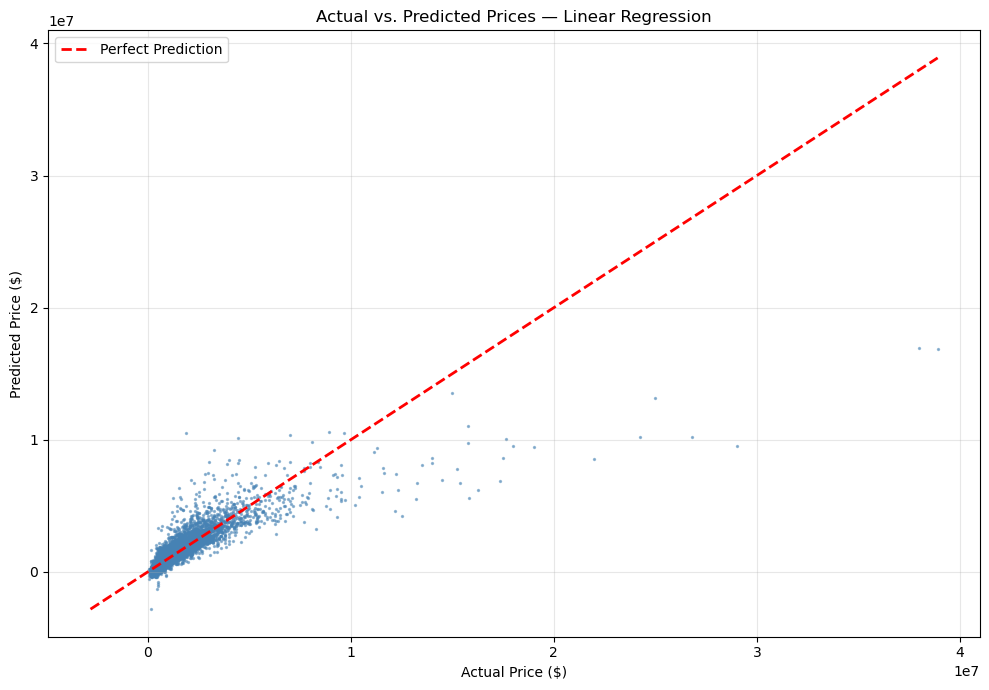

In [20]:
def plot_actual_vs_predicted(y_true, y_pred, model_name="Model"):

    actual = np.asarray(y_true).ravel()
    predicted = np.asarray(y_pred).ravel()

    plt.figure(figsize=(10, 7))

    plt.scatter(actual, predicted, alpha=0.5, s=2, color="steelblue")

    min_val = min(actual.min(), predicted.min())
    max_val = max(actual.max(), predicted.max())

    plt.plot(
        [min_val, max_val],
        [min_val, max_val],
        color="red",
        linestyle="--",
        linewidth=2,
        label="Perfect Prediction"
    )

    plt.xlabel("Actual Price ($)")
    plt.ylabel("Predicted Price ($)")
    plt.title(f"Actual vs. Predicted Prices — {model_name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_actual_vs_predicted(y_val, lr_val_pred_A, "Linear Regression")

In [21]:

def tune_model(model, param_dist, X_train, y_train, numeric_cols,
    bool_cols, categorical_cols, model_name="Model", X_val=None,
    y_val=None, n_iter=50, cv=5, random_state=42):

    preprocessor = build_preprocessor(
        numeric_cols,
        bool_cols,
        categorical_cols)

    model_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", model)])

    random_search = RandomizedSearchCV(
        estimator=model_pipeline,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring="neg_root_mean_squared_error",
        cv=cv,
        random_state=random_state,
        n_jobs=1,
        verbose=1)

    random_search.fit(X_train, y_train)

    best_model = random_search.best_estimator_

    print(f"\n{model_name} - Best Parameters:")
    print(random_search.best_params_)
    print(f"Best CV RMSE: ${-random_search.best_score_:,.2f}")

  
    train_pred = best_model.predict(X_train)

    train_results = evaluate_model(y_train, train_pred,
        model_name=model_name,
        report_name="TRAINING REPORT")

    val_pred = None
    val_results = None

    if X_val is not None and y_val is not None:
        val_pred = best_model.predict(X_val)
        val_results = evaluate_model(y_val, val_pred,
            model_name=model_name,
            report_name="VALIDATION REPORT")

    results = None

    if val_results is not None:
        results = {
            "Model": model_name,
            "Train R2": train_results["R2"],
            "Validation R2": val_results["R2"],
            "Train MAE": train_results["MAE"],
            "Validation MAE": val_results["MAE"],
            "Train RMSE": train_results["RMSE"],
            "Validation RMSE": val_results["RMSE"],
            "Train Median Absolute Error": train_results["Median Absolute Error"],
            "Validation Median Absolute Error": val_results["Median Absolute Error"],
            "Train MDAPE": train_results["MDAPE"],
            "Validation MDAPE": val_results["MDAPE"]}

    return (best_model, random_search, train_pred, val_pred, train_results,
        val_results, results)


In [22]:
dt_model = DecisionTreeRegressor(random_state = 42)

dt_param_dist = {
    "regressor__max_depth": [7, 10, 12, 15],
    "regressor__min_samples_split": [10, 15, 20],
    "regressor__min_samples_leaf": [5, 10, 15],
    "regressor__max_features": [None],
    "regressor__criterion": ["squared_error"],
    "regressor__ccp_alpha": [0.0, 0.001]}

(best_dt_model_A, dt_random_search_A, dt_train_pred_A, dt_val_pred_A,
    dt_train_results_A, dt_val_results_A, dt_results_A) = tune_model(
    model=DecisionTreeRegressor(random_state=42),
    param_dist=dt_param_dist,
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val,
    numeric_cols=numeric_cols_A,
    bool_cols=bool_cols_A,
    categorical_cols=categorical_cols_A,
    model_name="Decision Tree",
    n_iter=15,
    cv=5)

display(pd.DataFrame([dt_results_A]))


Fitting 5 folds for each of 15 candidates, totalling 75 fits

Decision Tree - Best Parameters:
{'regressor__min_samples_split': 15, 'regressor__min_samples_leaf': 10, 'regressor__max_features': None, 'regressor__max_depth': 15, 'regressor__criterion': 'squared_error', 'regressor__ccp_alpha': 0.0}
Best CV RMSE: $779,755.48

TRAINING REPORT - DECISION TREE
R2: 82.02%
MAE: $227,929.08
RMSE: $578,608.94
Median Absolute Error: $96,655.81
MDAPE: 10.75%

VALIDATION REPORT - DECISION TREE
R2: 75.75%
MAE: $268,325.57
RMSE: $694,496.59
Median Absolute Error: $104,175.14
MDAPE: 11.84%


,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,Decision Tree,82.018552,75.752656,227929.080254,268325.573705,578608.936677,694496.59242,96655.813596,104175.139244,10.75148,11.842363


In [23]:
fitted_models["Decision Tree Tuned"] = best_dt_model_A

validation_results.append(dt_results_A)

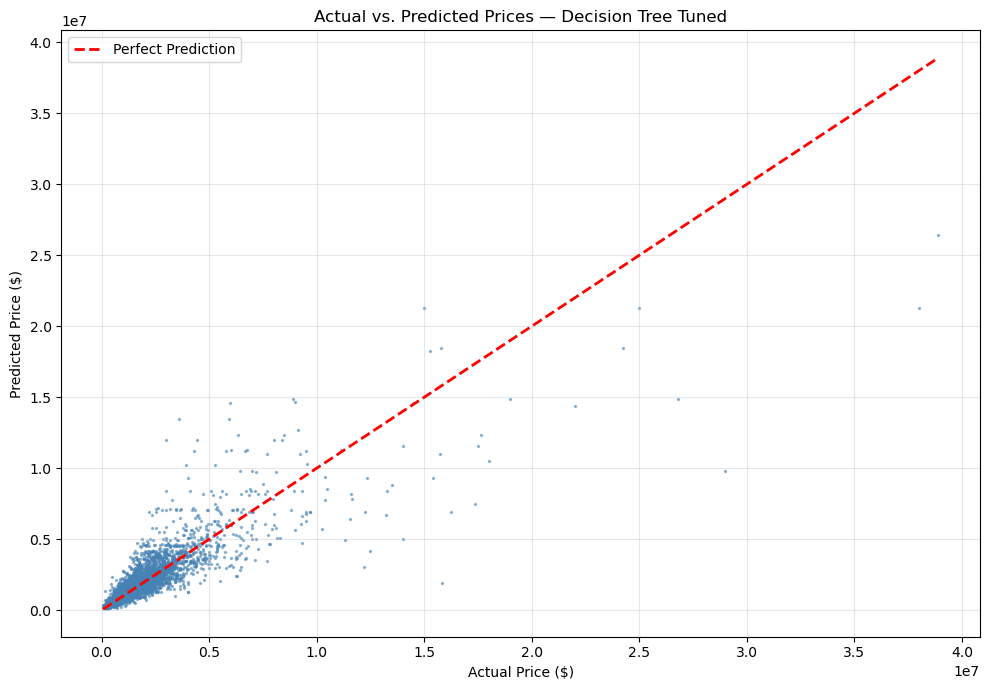

In [24]:
plot_actual_vs_predicted(y_val, dt_val_pred_A, "Decision Tree Tuned")

In [25]:

def train_random_forest(X_train, y_train, X_val, y_val,
    numeric_cols, bool_cols, categorical_cols,
    model_name="Random Forest"):

    preprocessor = build_preprocessor(
        numeric_cols,
        bool_cols,
        categorical_cols)

    rf_model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            max_depth=15,
            min_samples_split=5,
            min_samples_leaf=3,
            max_features=0.5,
            bootstrap=True,
            max_samples=0.8,
            random_state=42,
            n_jobs=-1))])

    rf_model.fit(X_train, y_train)

    rf_train_pred = rf_model.predict(X_train)
    rf_val_pred = rf_model.predict(X_val)

    rf_train_results = evaluate_model(y_train, rf_train_pred,
        model_name=model_name,
        report_name="TRAINING REPORT")

    rf_val_results = evaluate_model(y_val, rf_val_pred,
        model_name=model_name,
        report_name="VALIDATION REPORT")

    rf_results = {
        "Model": model_name,
        "Train R2": rf_train_results["R2"],
        "Validation R2": rf_val_results["R2"],
        "Train MAE": rf_train_results["MAE"],
        "Validation MAE": rf_val_results["MAE"],
        "Train RMSE": rf_train_results["RMSE"],
        "Validation RMSE": rf_val_results["RMSE"],
        "Train Median Absolute Error": rf_train_results["Median Absolute Error"],
        "Validation Median Absolute Error": rf_val_results["Median Absolute Error"],
        "Train MDAPE": rf_train_results["MDAPE"],
        "Validation MDAPE": rf_val_results["MDAPE"]}

    return (rf_model, rf_train_pred, rf_val_pred, rf_train_results, rf_val_results,
        rf_results)


In [26]:
(rf_model_A, rf_train_pred_A, rf_val_pred_A, rf_train_results_A,
    rf_val_results_A, rf_results_A) = train_random_forest(
    X_train, y_train,
    X_val, y_val,
    numeric_cols_A,
    bool_cols_A,
    categorical_cols_A)

display(pd.DataFrame([rf_results_A]))
fitted_models["Random Forest"] = rf_model_A

validation_results.append(rf_results_A)



TRAINING REPORT - RANDOM FOREST
R2: 87.85%
MAE: $193,350.61
RMSE: $475,572.35
Median Absolute Error: $89,480.19
MDAPE: 9.68%

VALIDATION REPORT - RANDOM FOREST
R2: 82.77%
MAE: $224,496.30
RMSE: $585,367.99
Median Absolute Error: $92,470.76
MDAPE: 10.34%


,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,Random Forest,87.852482,82.774102,193350.612221,224496.295861,475572.34538,585367.992544,89480.190081,92470.764867,9.68125,10.338137


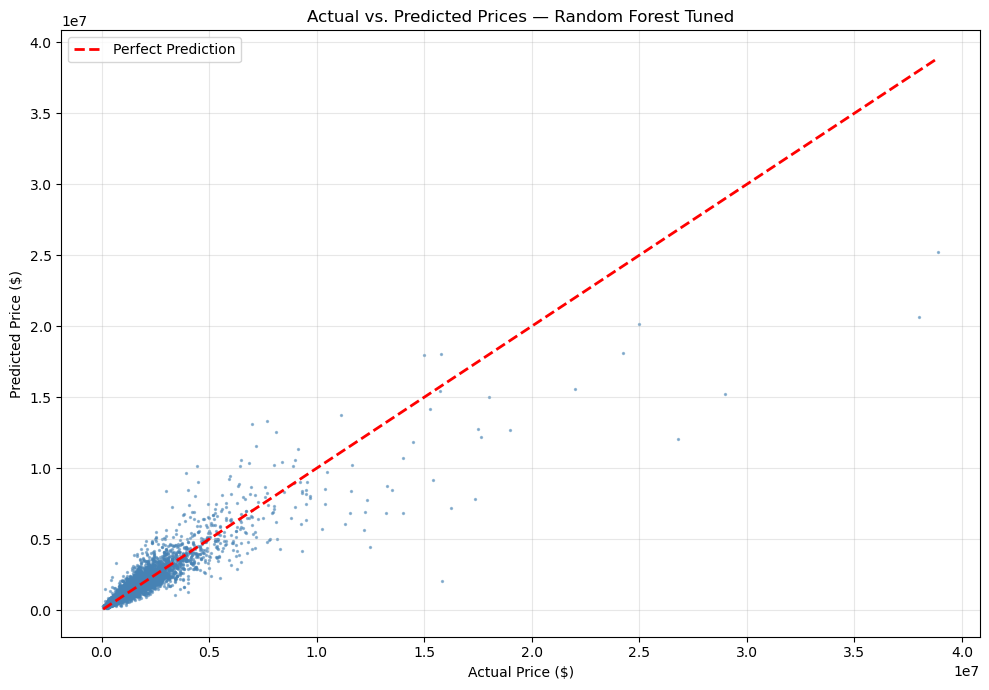

In [27]:
plot_actual_vs_predicted(y_val, rf_val_pred_A, "Random Forest Tuned")

In [28]:
model_comparison_A = pd.DataFrame([
    lr_results_A,
    dt_results_A,
    rf_results_A])

model_comparison_A = model_comparison_A.sort_values(
    by="Validation RMSE",
    ascending=True
).reset_index(drop=True)

display(model_comparison_A)

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,Random Forest,87.852482,82.774102,193350.612221,224496.295861,475572.345380,585367.992544,89480.190081,92470.764867,9.681250,10.338137
1,Decision Tree,82.018552,75.752656,227929.080254,268325.573705,578608.936677,694496.592420,96655.813596,104175.139244,10.751480,11.842363
2,Linear Regression,73.178639,71.237392,315152.853271,330557.308963,706664.405465,756401.119975,193890.021517,197343.520368,20.288879,20.782780


Linear Regression has a small training-validation performance gap, suggesting consistent generalization. It has relatively high prediction errors indicating that it might not capture complex relationship between property characteristics and prices.

Decision Tree captures nonlinear patterns and shows improvement in prediction accuracy over Linear Regression, but it is more prone to overfitting since the patterns do not generalize well to unseen properties.

Random Forest provides the strongest overall predictive performance by capturing complex relationships while reducing the instability of an individual tree. The Random Forest achieves the highest validation $R^2$ of 81.05% and lowest validation MAE among the three models. It's main weakness is that the prediction errors are still high. Overall, it offers the best trade-off between predictive accuray and generalization. 

In [29]:
X_train_original = X_train.copy(deep=True)
X_val_original = X_val.copy(deep=True)

def add_property_features(X, reference_year=2026):
    X = X.copy()

    bedrooms = pd.to_numeric(X["BedroomsTotal"], errors="coerce")

    bathrooms = pd.to_numeric(X["BathroomsTotalInteger"], errors="coerce").replace(0, np.nan)

    X["Bed_Bath_Ratio"] = bedrooms / bathrooms

    year_built = pd.to_numeric(X["YearBuilt"], errors="coerce")

    X["PropertyAge"] = (reference_year - year_built).where(year_built <= reference_year)

    living_area = pd.to_numeric(X["LivingArea"], errors="coerce")

    X["LogLivingArea"] = np.log1p(living_area.where(living_area >= 0))

    return X

X_train = add_property_features(X_train, reference_year=2026)

X_val = add_property_features(X_val, reference_year=2026)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nNew features:")
print(["Bed_Bath_Ratio", "PropertyAge", "LogLivingArea"])

assert X_train.columns.equals(X_val.columns)

Training shape: (110406, 19)
Validation shape: (11312, 19)

New features:
['Bed_Bath_Ratio', 'PropertyAge', 'LogLivingArea']


In [30]:
path_geo = Path("DistrictAreas2526.geojson")
districts = gpd.read_file(path_geo)

print("Number of school districts:", len(districts))
print("District CRS:", districts.crs)

def add_school_district(X, districts):
    X = X.copy()

    original_index = X.index.copy()
    X["_row_id"] = np.arange(len(X))

    points = gpd.GeoDataFrame(
        X[["_row_id"]].copy(), geometry=gpd.points_from_xy(
            X["Longitude"],
            X["Latitude"]), crs="EPSG:4326")

    district_shapes = districts.to_crs("EPSG:4326")

    joined = gpd.sjoin(
        points,
        district_shapes[["DistrictName", "geometry"]],
        how="left",
        predicate="within")

    district_map = (
        joined.drop_duplicates("_row_id")
        .set_index("_row_id")["DistrictName"])

    X["SchoolDistrict"] = X["_row_id"].map(district_map)

    X = X.drop(columns=["_row_id"])

    X.index = original_index

    return X

    

Number of school districts: 936
District CRS: EPSG:4326


In [31]:
X_train = add_school_district(X_train, districts)

X_val = add_school_district(X_val, districts)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

print("\nTraining missing school districts:",
      X_train["SchoolDistrict"].isna().sum())

print("Validation missing school districts:",
      X_val["SchoolDistrict"].isna().sum())

assert X_train.columns.equals(X_val.columns)


Training shape: (110406, 20)
Validation shape: (11312, 20)

Training missing school districts: 7
Validation missing school districts: 0


In [32]:

def add_zipcode_ppsf_encoding(
    X_train, X_val,
    X_train_original, X_val_original,
    y_train, train_scoped, val_scoped,
    reference_date="2026-07-31",
    n_splits=5, min_zip_samples=5):

    X_train = X_train.copy()
    X_val = X_val.copy()

    assert X_train_original.index.equals(X_train.index)
    assert X_val_original.index.equals(X_val.index)
    assert X_train_original.index.is_unique
    assert X_val_original.index.is_unique

    y_train = pd.Series(
        np.asarray(y_train).ravel(),
        index=X_train_original.index)

    if y_train.isna().any():
        raise ValueError("Missing training target values.")

    reference_date = pd.Timestamp(reference_date)
    cutoff_date = reference_date - pd.DateOffset(months=12)

    close_dates = pd.to_datetime(
        train_scoped.reindex(X_train_original.index)["CloseDate"],
        errors="coerce")

    sqft = pd.to_numeric(
        X_train_original["LivingArea"], errors="coerce").where(lambda s: s > 0)

    train_ppsf = y_train / sqft

    recent_mask = (
        (close_dates >= cutoff_date) &
        (close_dates <= reference_date))

    train_ppsf = train_ppsf.where(recent_mask)

    train_ppsf = train_ppsf.where(
        np.isfinite(train_ppsf) & (train_ppsf > 0))

    valid_mask = train_ppsf.notna()

    if valid_mask.sum() == 0:
        raise ValueError("No valid training PPSF observations.")

    feature = "zipcode_median_ppsf"

    X_train[feature] = np.nan
    
    unique_dates = np.sort(
        close_dates.loc[valid_mask].unique())

    if len(unique_dates) <= n_splits:
        raise ValueError("Not enough unique dates for chronological folds.")

    tscv = TimeSeriesSplit(n_splits=n_splits)

    for train_idx, val_idx in tscv.split(unique_dates):

        fold_train_dates = unique_dates[train_idx]
        fold_val_dates = unique_dates[val_idx]

        fold_train_mask = (
            close_dates.isin(fold_train_dates) & valid_mask)

        fold_val_mask = close_dates.isin(fold_val_dates)

        fold_data = pd.DataFrame({
            "PostalCode": X_train_original.loc[
                fold_train_mask, "PostalCode"],
            "PPSF": train_ppsf.loc[fold_train_mask]}).dropna()

        if fold_data.empty:
            continue

        zip_stats = fold_data.groupby("PostalCode")["PPSF"].agg(
            ["median", "count"])

        zip_medians = zip_stats.loc[
            zip_stats["count"] >= min_zip_samples, "median"]

        global_median = fold_data["PPSF"].median()

        encoded = (
            X_train_original.loc[fold_val_mask, "PostalCode"]
            .map(zip_medians).fillna(global_median))

        X_train.loc[fold_val_mask, feature] = encoded

    full_data = pd.DataFrame({
        "PostalCode": X_train_original["PostalCode"],
        "PPSF": train_ppsf}).dropna()

    zip_stats = full_data.groupby("PostalCode")["PPSF"].agg(
        ["median", "count"])

    zip_medians = zip_stats.loc[
        zip_stats["count"] >= min_zip_samples, "median"]

    global_ppsf_median = train_ppsf.median()

    X_val[feature] = (
        X_val_original["PostalCode"]
        .map(zip_medians).fillna(global_ppsf_median))
    
    X_train[feature] = X_train[feature].fillna(global_ppsf_median)

    assert X_train[feature].notna().all()
    assert X_val[feature].notna().all()

    print("\nZIP-CODE PPSF ENCODING REPORT")
    print("=" * 50)
    print("Training encoded:", X_train[feature].notna().sum())
    print("Validation encoded:", X_val[feature].notna().sum())
    print("Valid training PPSF:", train_ppsf.notna().sum())
    print("Number of ZIP codes:", len(zip_medians))
    print("Global PPSF median:", round(global_ppsf_median, 2))
    print("Reference date:", reference_date.date())
    print("Cutoff date:", cutoff_date.date())

    ppsf_stats = {
        "zip_medians": zip_medians.copy(),
        "global_ppsf_median": global_ppsf_median,
        "min_zip_samples": min_zip_samples,
        "reference_date": reference_date,
        "cutoff_date": cutoff_date}

    return X_train, X_val, ppsf_stats


In [33]:
X_train, X_val, ppsf_stats = add_zipcode_ppsf_encoding(
    X_train, X_val,
    X_train_original, X_val_original,
    y_train, train_scoped, val_scoped,
    reference_date="2026-07-31",
    n_splits=5, min_zip_samples=5)


ZIP-CODE PPSF ENCODING REPORT
Training encoded: 110406
Validation encoded: 11312
Valid training PPSF: 110406
Number of ZIP codes: 1088
Global PPSF median: 526.8
Reference date: 2026-07-31
Cutoff date: 2025-07-31


In [34]:

def configure_features_B(X_train, X_val,
    numeric_cols, bool_cols, categorical_cols,
    X_test=None, test_only=False,
    expected_columns=None):

    numeric_cols = list(numeric_cols)
    bool_cols = list(bool_cols)
    categorical_cols = list(categorical_cols)

    new_numeric_cols = [
        "Bed_Bath_Ratio",
        "PropertyAge",
        "zipcode_median_ppsf",
        "LogLivingArea"]

    new_categorical_cols = ["SchoolDistrict"]

    cols_to_remove = [
        "YearBuilt",
        "LivingArea",
        "BedroomsTotal",
        "BathroomsTotalInteger"]

    for col in new_numeric_cols:
        if col not in numeric_cols:
            numeric_cols.append(col)

    for col in new_categorical_cols:
        if col not in categorical_cols:
            categorical_cols.append(col)

    if test_only:

        if X_test is None:
            raise ValueError("X_test must be provided.")

        X_test = X_test.copy()

        for col in new_numeric_cols + new_categorical_cols:
            if col not in X_test.columns:
                raise ValueError(f"Missing engineered test feature: {col}")

        X_test = X_test.drop(columns=cols_to_remove, errors="ignore")

        if expected_columns is not None:
            missing = set(expected_columns) - set(X_test.columns)

            if missing:
                raise ValueError(f"Missing test columns: {missing}")

            X_test = X_test.reindex(columns=expected_columns)

        return X_test

    X_train = X_train.copy()
    X_val = X_val.copy()

    for col in new_numeric_cols + new_categorical_cols:
        if col not in X_train.columns or col not in X_val.columns:
            raise ValueError(f"Missing engineered feature: {col}")

    X_train = X_train.drop(columns=cols_to_remove, errors="ignore")

    X_val = X_val.drop(columns=cols_to_remove, errors="ignore")

    numeric_cols_B = [col for col in numeric_cols if col in X_train.columns]

    bool_cols_B = [col for col in bool_cols if col in X_train.columns]

    categorical_cols_B = [col for col in categorical_cols if col in X_train.columns]

    all_features = (
        numeric_cols_B +
        bool_cols_B +
        categorical_cols_B)

    if len(all_features) != len(set(all_features)):
        raise ValueError("Duplicate features detected.")

    assert X_train.columns.equals(X_val.columns)
    assert set(all_features).issubset(X_train.columns)

    print("Feature Set B")
    print("Numeric:", numeric_cols_B)
    print("Boolean:", bool_cols_B)
    print("Categorical:", categorical_cols_B)
    print("Training:", X_train.shape)
    print("Validation:", X_val.shape)

    return (X_train, X_val, numeric_cols_B, bool_cols_B, categorical_cols_B)


In [35]:
(X_train_B, X_val_B, numeric_cols_B, bool_cols_B,
    categorical_cols_B) = configure_features_B(
    X_train, X_val,
    numeric_cols_A,
    bool_cols_A,
    categorical_cols_A)


Feature Set B
Numeric: ['Latitude', 'Longitude', 'LotSizeSquareFeet', 'Stories', 'GarageSpaces', 'city_median_price', 'Bed_Bath_Ratio', 'PropertyAge', 'zipcode_median_ppsf', 'LogLivingArea']
Boolean: ['NewConstructionYN', 'PoolPrivateYN', 'ViewYN', 'FireplaceYN']
Categorical: ['PostalCode', 'CountyOrParish', 'SchoolDistrict']
Training: (110406, 17)
Validation: (11312, 17)


In [36]:
fitted_models_B = {}
validation_results_B = []

lr_model_B, lr_train_pred_B, lr_val_pred_B, lr_results_B = train_and_evaluate_model(
    model=LinearRegression(),
    model_name="Linear Regression - Feature B",
    X_train=X_train_B,
    y_train=y_train,
    X_val=X_val_B,
    y_val=y_val,
    numeric_cols=numeric_cols_B,
    bool_cols=bool_cols_B,
    categorical_cols=categorical_cols_B
)

fitted_models_B["Linear Regression"] = lr_model_B
validation_results_B.append(lr_results_B)



TRAINING REPORT - LINEAR REGRESSION - FEATURE B
R2: 67.59%
MAE: $340,542.82
RMSE: $776,838.08
Median Absolute Error: $213,133.60
MDAPE: 21.79%

VALIDATION REPORT - LINEAR REGRESSION - FEATURE B
R2: 62.64%
MAE: $360,025.40
RMSE: $862,101.80
Median Absolute Error: $219,862.14
MDAPE: 22.37%


In [37]:
dt_param_dist_B = {
    "regressor__max_depth": [4, 5, 6, 7, 8, 10],
    "regressor__min_samples_split": [20, 30, 40, 50],
    "regressor__min_samples_leaf": [10, 15, 20, 30],
    "regressor__max_features": [None, 0.7, 0.8, 0.9],
    "regressor__criterion": ["squared_error", "friedman_mse"],
    "regressor__ccp_alpha": [0.001, 0.005, 0.01, 0.02]}

(dt_model_B, dt_random_search_B, dt_train_pred_B, dt_val_pred_B,
    dt_train_results_B, dt_val_results_B, dt_results_B) = tune_model(
    model=DecisionTreeRegressor(random_state=42),
    param_dist=dt_param_dist_B,
    X_train=X_train_B,
    y_train=y_train,
    X_val=X_val_B,
    y_val=y_val,
    numeric_cols=numeric_cols_B,
    bool_cols=bool_cols_B,
    categorical_cols=categorical_cols_B,
    model_name="Decision Tree - Feature B",
    n_iter=40,
    cv=5)

fitted_models_B["Decision Tree"] = dt_model_B
validation_results_B.append(dt_results_B)

display(pd.DataFrame([dt_results_B]).round(3))


Fitting 5 folds for each of 40 candidates, totalling 200 fits

Decision Tree - Feature B - Best Parameters:
{'regressor__min_samples_split': 40, 'regressor__min_samples_leaf': 30, 'regressor__max_features': None, 'regressor__max_depth': 8, 'regressor__criterion': 'squared_error', 'regressor__ccp_alpha': 0.001}
Best CV RMSE: $760,135.91

TRAINING REPORT - DECISION TREE - FEATURE B
R2: 75.04%
MAE: $291,512.97
RMSE: $681,748.20
Median Absolute Error: $141,512.28
MDAPE: 15.45%

VALIDATION REPORT - DECISION TREE - FEATURE B
R2: 79.40%
MAE: $262,729.65
RMSE: $640,156.08
Median Absolute Error: $127,950.79
MDAPE: 14.38%


,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,Decision Tree - Feature B,75.037,79.399,291512.967,262729.651,681748.201,640156.084,141512.282,127950.789,15.449,14.382


In [38]:
(rf_model_B, rf_train_pred_B, rf_val_pred_B, rf_train_results_B,
    rf_val_results_B, rf_results_B) = train_random_forest(
    X_train_B, y_train,
    X_val_B, y_val,
    numeric_cols_B,
    bool_cols_B,
    categorical_cols_B,
    model_name="Random Forest - Feature B")

fitted_models_B["Random Forest"] = rf_model_B
validation_results_B.append(rf_results_B)



TRAINING REPORT - RANDOM FOREST - FEATURE B
R2: 88.60%
MAE: $184,482.71
RMSE: $460,632.33
Median Absolute Error: $84,861.38
MDAPE: 9.10%

VALIDATION REPORT - RANDOM FOREST - FEATURE B
R2: 84.13%
MAE: $202,121.31
RMSE: $561,813.76
Median Absolute Error: $84,321.79
MDAPE: 9.34%


In [39]:
results_B_df = pd.DataFrame(validation_results_B)

display(results_B_df.sort_values(by="Validation MAE",
        ascending=True))


,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
2,Random Forest - Feature B,88.603717,84.132494,184482.713524,202121.308567,460632.331393,561813.762460,84861.381297,84321.788935,9.101928,9.338302
1,Decision Tree - Feature B,75.036678,79.398650,291512.967055,262729.651010,681748.201410,640156.084233,141512.281511,127950.788732,15.448990,14.381651
0,Linear Regression - Feature B,67.587286,62.637060,340542.815231,360025.396748,776838.084774,862101.803959,213133.599741,219862.137021,21.787439,22.370965


In [40]:
comparison = pd.DataFrame({
    "Feature Type": ["Numeric", "Boolean", "Categorical"],
    "Features A": [
        ", ".join(numeric_cols_A),
        ", ".join(bool_cols_A),
        ", ".join(categorical_cols_A)
    ],
    "Features B": [
        ", ".join(numeric_cols_B),
        ", ".join(bool_cols_B),
        ", ".join(categorical_cols_B)]})

display(Markdown("## Features A vs Features B"))
display(comparison.style.hide(axis="index"))


## Features A vs Features B

Feature Type,Features A,Features B
Numeric,"LivingArea, BedroomsTotal, BathroomsTotalInteger, Latitude, Longitude, LotSizeSquareFeet, YearBuilt, Stories, GarageSpaces, city_median_price","Latitude, Longitude, LotSizeSquareFeet, Stories, GarageSpaces, city_median_price, Bed_Bath_Ratio, PropertyAge, zipcode_median_ppsf, LogLivingArea"
Boolean,"NewConstructionYN, PoolPrivateYN, ViewYN, FireplaceYN","NewConstructionYN, PoolPrivateYN, ViewYN, FireplaceYN"
Categorical,"PostalCode, CountyOrParish","PostalCode, CountyOrParish, SchoolDistrict"


In [41]:
results_comparison = pd.DataFrame([
    {"Feature Set": "A", **lr_results_A},
    {"Feature Set": "B", **lr_results_B},

    {"Feature Set": "A", **dt_results_A},
    {"Feature Set": "B", **dt_results_B},

    {"Feature Set": "A", **rf_results_A},
    {"Feature Set": "B", **rf_results_B}])

results_comparison = results_comparison.sort_values(
    by=["Model", "Feature Set"]).reset_index(drop=True)

display(results_comparison)

,Feature Set,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,A,Decision Tree,82.018552,75.752656,227929.080254,268325.573705,578608.936677,694496.592420,96655.813596,104175.139244,10.751480,11.842363
1,B,Decision Tree - Feature B,75.036678,79.398650,291512.967055,262729.651010,681748.201410,640156.084233,141512.281511,127950.788732,15.448990,14.381651
2,A,Linear Regression,73.178639,71.237392,315152.853271,330557.308963,706664.405465,756401.119975,193890.021517,197343.520368,20.288879,20.782780
3,B,Linear Regression - Feature B,67.587286,62.637060,340542.815231,360025.396748,776838.084774,862101.803959,213133.599741,219862.137021,21.787439,22.370965
4,A,Random Forest,87.852482,82.774102,193350.612221,224496.295861,475572.345380,585367.992544,89480.190081,92470.764867,9.681250,10.338137
5,B,Random Forest - Feature B,88.603717,84.132494,184482.713524,202121.308567,460632.331393,561813.762460,84861.381297,84321.788935,9.101928,9.338302


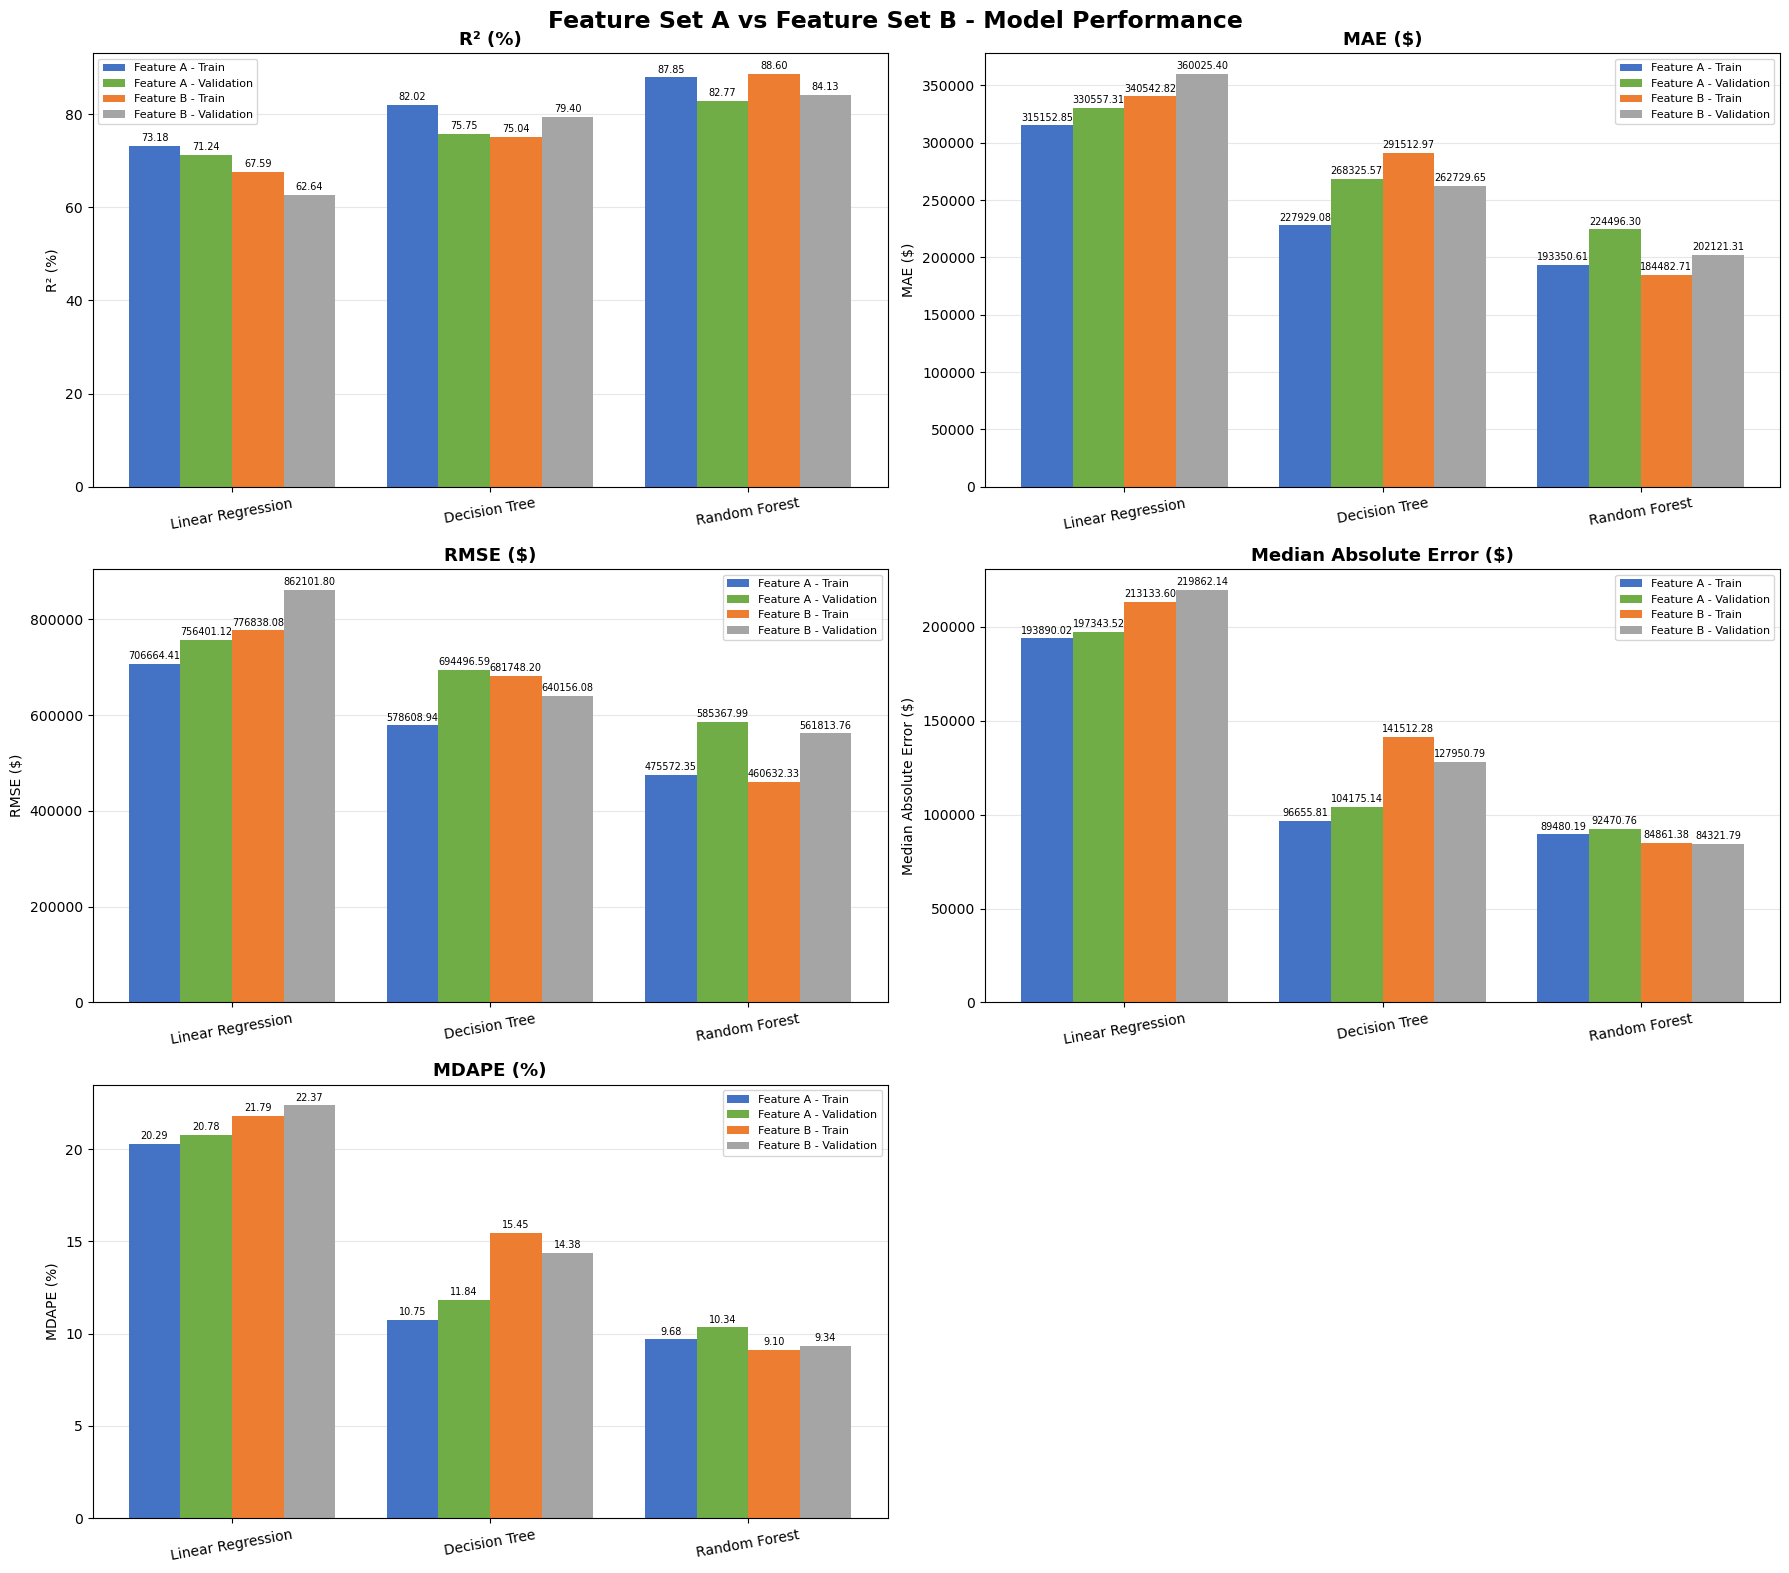

In [42]:
metrics = [
    ("R2", "R² (%)"),
    ("MAE", "MAE ($)"),
    ("RMSE", "RMSE ($)"),
    ("Median Absolute Error", "Median Absolute Error ($)"),
    ("MDAPE", "MDAPE (%)")]

models = ["Linear Regression", "Decision Tree", "Random Forest"]

fig, axes = plt.subplots(3, 2, figsize=(18, 16))
axes = axes.flatten()

x = np.arange(len(models))
width = 0.20

colors = {
    "A_train": "#4472C4",
    "A_val": "#70AD47",
    "B_train": "#ED7D31",
    "B_val": "#A5A5A5"}

for i, (metric, title) in enumerate(metrics):
    ax = axes[i]
    for j, (feature_set, dataset, offset, color) in enumerate([
        ("A", "Train", -1.5 * width, colors["A_train"]),
        ("A", "Validation", -0.5 * width, colors["A_val"]),
        ("B", "Train", 0.5 * width, colors["B_train"]),
        ("B", "Validation", 1.5 * width, colors["B_val"])]):

        values = []

        for model in models:
            row = results_comparison[
                (results_comparison["Model"].str.contains(model, case=False)) &
                (results_comparison["Feature Set"] == feature_set)]

            values.append(row[f"{dataset} {metric}"].iloc[0])

        bars = ax.bar(x + offset, values, width,
            label=f"Feature {feature_set} - {dataset}", color=color)

        ax.bar_label(bars, fmt="%.2f", fontsize=7, padding=2)

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(models, rotation=10)
    ax.set_ylabel(title)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    ax.legend(fontsize=8)

fig.delaxes(axes[5])

plt.suptitle(
    "Feature Set A vs Feature Set B - Model Performance",
    fontsize=17, fontweight="bold")

plt.tight_layout()
plt.show()


In [43]:
validation_metrics = [
    "Validation R2",
    "Validation MAE",
    "Validation RMSE",
    "Validation Median Absolute Error",
    "Validation MDAPE"]

validation_comparison = results_comparison[
    ["Model", "Feature Set"] + validation_metrics].sort_values(
    by="Validation R2", ascending=False).reset_index(drop=True)

display(validation_comparison)


,Model,Feature Set,Validation R2,Validation MAE,Validation RMSE,Validation Median Absolute Error,Validation MDAPE
0,Random Forest - Feature B,B,84.132494,202121.308567,561813.762460,84321.788935,9.338302
1,Random Forest,A,82.774102,224496.295861,585367.992544,92470.764867,10.338137
2,Decision Tree - Feature B,B,79.398650,262729.651010,640156.084233,127950.788732,14.381651
3,Decision Tree,A,75.752656,268325.573705,694496.592420,104175.139244,11.842363
4,Linear Regression,A,71.237392,330557.308963,756401.119975,197343.520368,20.782780
5,Linear Regression - Feature B,B,62.637060,360025.396748,862101.803959,219862.137021,22.370965


In [44]:
improvement = []

for model in models:
    result_A = results_comparison[
        (results_comparison["Feature Set"] == "A") &
        (results_comparison["Model"].str.contains(model, case=False))].iloc[0]

    result_B = results_comparison[
        (results_comparison["Feature Set"] == "B") &
        (results_comparison["Model"].str.contains(model, case=False))].iloc[0]

    improvement.append({
        "Model": model,
        "R2 Improvement (%)":
            result_B["Validation R2"] - result_A["Validation R2"],
        "MAE Improvement (%)":
            (result_A["Validation MAE"] - result_B["Validation MAE"])
            / result_A["Validation MAE"] * 100,
        "RMSE Improvement (%)":
            (result_A["Validation RMSE"] - result_B["Validation RMSE"])
            / result_A["Validation RMSE"] * 100,
        "Median AE Improvement (%)":
            (result_A["Validation Median Absolute Error"] -
             result_B["Validation Median Absolute Error"])
            / result_A["Validation Median Absolute Error"] * 100,
        "MDAPE Improvement (%)":
            (result_A["Validation MDAPE"] - result_B["Validation MDAPE"])
            / result_A["Validation MDAPE"] * 100})

improvement_df = pd.DataFrame(improvement)

display(improvement_df.round(2))


,Model,R2 Improvement (%),MAE Improvement (%),RMSE Improvement (%),Median AE Improvement (%),MDAPE Improvement (%)
0,Linear Regression,-8.60,-8.91,-13.97,-11.41,-7.64
1,Decision Tree,3.65,2.09,7.82,-22.82,-21.44
2,Random Forest,1.36,9.97,4.02,8.81,9.67


The results show that Random Forest performed the best overall on the validation data for both feature sets. With Features B, its $R^2$ increased slightly from 82.68% to 83.65%, and its MAE and RMSE also decreased, meaning its predictions were slightly more accurate. Linear Regression also improved with Features B, while the Decision Tree performed better Features A. The training results were generally better than the validation results, especially for Random Forest, whichi suggests tthe model may be overfitting to some extent. Overall, Features B seems to be a better choice for Linear Regression and Random Forest, while Features A works better for the Decision Tree. 

In [45]:
from scipy.stats import randint, uniform, loguniform

def tune_xgboost(X_train, y_train, X_val, y_val,
    numeric_cols, bool_cols, categorical_cols,
    model_name="XGBoost - Features B",
    n_iter=30, cv=5, random_state=42, n_jobs=-1):

    preprocessor = build_preprocessor(
        numeric_cols,
        bool_cols,
        categorical_cols)

    xgb_pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", XGBRegressor(
            objective="reg:squarederror",
            eval_metric="rmse",
            tree_method="hist",
            random_state=random_state,
            n_jobs=1))])

    param_dist = {
        "regressor__n_estimators": randint(450, 651),
        "regressor__max_depth": [5, 6],
        "regressor__learning_rate": loguniform(0.09, 0.15),
        "regressor__min_child_weight": [5, 7, 8],
        "regressor__subsample": uniform(0.90, 0.10),
        "regressor__colsample_bytree": uniform(0.78, 0.15),
        "regressor__gamma": uniform(0.20, 0.15),
        "regressor__reg_alpha": [0.01, 0.1, 1.0],
        "regressor__reg_lambda": [1, 2, 3],
        "regressor__max_delta_step": [0]}

    tscv = TimeSeriesSplit(n_splits=cv)

    random_search = RandomizedSearchCV(
        estimator=xgb_pipeline,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        refit=True,
        random_state=random_state,
        n_jobs=n_jobs,
        verbose=1,
        return_train_score=False)

    random_search.fit(X_train, y_train)

    best_model = random_search.best_estimator_

    print(f"\n{model_name} - BEST PARAMETERS")
    print(random_search.best_params_)
    print("\nBest CV RMSE:", f"${-random_search.best_score_:,.2f}")

    train_pred = best_model.predict(X_train)

    train_results = evaluate_model(y_train, train_pred,
        model_name=model_name,
        report_name="TRAINING REPORT")

    val_pred = best_model.predict(X_val)

    val_results = evaluate_model(y_val, val_pred,
        model_name=model_name,
        report_name="VALIDATION REPORT")

    results = {
        "Model": model_name,
        "Train R2": train_results["R2"],
        "Validation R2": val_results["R2"],
        "Train MAE": train_results["MAE"],
        "Validation MAE": val_results["MAE"],
        "Train RMSE": train_results["RMSE"],
        "Validation RMSE": val_results["RMSE"],
        "Train Median Absolute Error":
            train_results["Median Absolute Error"],
        "Validation Median Absolute Error":
            val_results["Median Absolute Error"],
        "Train MDAPE": train_results["MDAPE"],
        "Validation MDAPE": val_results["MDAPE"]}

    return (best_model, random_search, train_pred, val_pred,
        train_results, val_results, results)


In [46]:
(xgb_model_B, xgb_random_search_B, xgb_train_pred_B,
    xgb_val_pred_B, xgb_train_results_B, xgb_val_results_B,
    xgb_results_B) = tune_xgboost(
    X_train=X_train_B,
    y_train=y_train,
    X_val=X_val_B,
    y_val=y_val,
    numeric_cols=numeric_cols_B,
    bool_cols=bool_cols_B,
    categorical_cols=categorical_cols_B,
    model_name="XGBoost - Feature B",
    n_iter=30,
    cv=5)

fitted_models_B["XGBoost"] = xgb_model_B

validation_results_B.append(xgb_results_B)


Fitting 5 folds for each of 30 candidates, totalling 150 fits

XGBoost - Feature B - BEST PARAMETERS
{'regressor__colsample_bytree': np.float64(0.7926209947492574), 'regressor__gamma': np.float64(0.22424430711419208), 'regressor__learning_rate': np.float64(0.14242480470778496), 'regressor__max_delta_step': 0, 'regressor__max_depth': 6, 'regressor__min_child_weight': 7, 'regressor__n_estimators': 561, 'regressor__reg_alpha': 0.1, 'regressor__reg_lambda': 1, 'regressor__subsample': np.float64(0.9663501769108056)}

Best CV RMSE: $592,245.23

TRAINING REPORT - XGBOOST - FEATURE B
R2: 93.55%
MAE: $165,422.97
RMSE: $346,657.01
Median Absolute Error: $85,580.69
MDAPE: 9.51%

VALIDATION REPORT - XGBOOST - FEATURE B
R2: 84.88%
MAE: $195,696.54
RMSE: $548,503.47
Median Absolute Error: $85,435.06
MDAPE: 9.54%


In [47]:

def tune_lightgbm(X_train, y_train, X_val, y_val,
    numeric_cols, bool_cols, categorical_cols,
    model_name="LightGBM - Features B",
    n_iter=15, cv=5, random_state=42, n_jobs=-1):

    X_train = X_train.copy()
    X_val = X_val.copy()

    for col in categorical_cols:
        X_train[col] = X_train[col].astype("category")
        categories = X_train[col].cat.categories

        X_val[col] = pd.Categorical(X_val[col], categories=categories)

    lgb_model = lgb.LGBMRegressor(
        objective="regression",
        random_state=random_state,
        n_jobs=1,
        verbosity=-1,
        max_bin=127,
        force_col_wise=True)

    param_grid = {
        "max_depth": [8, 10],
        "num_leaves": [31, 40],
        "learning_rate": [0.02, 0.03, 0.05],
        "n_estimators": [700, 900, 1000],
        "min_child_samples": [20, 30],
        "subsample": [0.85, 0.9, 1.0],
        "subsample_freq": [1],
        "colsample_bytree": [0.85, 0.9, 1.0],
        "reg_alpha": [0.1, 0.5, 1.0],
        "reg_lambda": [0.5, 1.0]}

    tscv = TimeSeriesSplit(n_splits=cv)

    random_search = RandomizedSearchCV(
        estimator=lgb_model,
        param_distributions=param_grid,
        n_iter=n_iter,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        refit=True,
        verbose=1,
        random_state=random_state,
        n_jobs=n_jobs,
        return_train_score=False,
        error_score="raise")

    random_search.fit(X_train, y_train, categorical_feature=categorical_cols)

    best_model = random_search.best_estimator_

    print(f"\n{model_name} - BEST PARAMETERS")
    print(random_search.best_params_)

    print("\nBEST CROSS-VALIDATION RMSE:")
    print(f"${-random_search.best_score_:,.2f}")
    
    train_pred = best_model.predict(X_train)

    train_results = evaluate_model(y_train, train_pred,
        model_name=model_name,
        report_name="TRAINING REPORT")
    
    val_pred = best_model.predict(X_val)

    val_results = evaluate_model(y_val, val_pred,
        model_name=model_name,
        report_name="VALIDATION REPORT")

    results = {
        "Model": model_name,
        "Train R2": train_results["R2"],
        "Validation R2": val_results["R2"],
        "Train MAE": train_results["MAE"],
        "Validation MAE": val_results["MAE"],
        "Train RMSE": train_results["RMSE"],
        "Validation RMSE": val_results["RMSE"],
        "Train Median Absolute Error":
            train_results["Median Absolute Error"],
        "Validation Median Absolute Error":
            val_results["Median Absolute Error"],
        "Train MDAPE": train_results["MDAPE"],
        "Validation MDAPE": val_results["MDAPE"]
    }

    return (best_model, random_search, train_pred, val_pred, train_results,
        val_results, results)



In [48]:
(lgb_model_B,lgb_random_search_B, lgb_train_pred_B, lgb_val_pred_B,
    lgb_train_results_B, lgb_val_results_B, lgb_results_B) = tune_lightgbm(
    X_train=X_train_B,
    y_train=y_train,
    X_val=X_val_B,
    y_val=y_val,
    numeric_cols=numeric_cols_B,
    bool_cols=bool_cols_B,
    categorical_cols=categorical_cols_B,
    model_name="LightGBM - Feature B",
    n_iter=15,
    cv=5)

fitted_models_B["LightGBM"] = lgb_model_B

validation_results_B.append(lgb_results_B)


Fitting 5 folds for each of 15 candidates, totalling 75 fits

LightGBM - Feature B - BEST PARAMETERS
{'subsample_freq': 1, 'subsample': 0.85, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'num_leaves': 40, 'n_estimators': 700, 'min_child_samples': 30, 'max_depth': 10, 'learning_rate': 0.02, 'colsample_bytree': 0.9}

BEST CROSS-VALIDATION RMSE:
$586,801.75

TRAINING REPORT - LIGHTGBM - FEATURE B
R2: 91.67%
MAE: $168,376.99
RMSE: $393,754.18
Median Absolute Error: $79,429.59
MDAPE: 8.87%

VALIDATION REPORT - LIGHTGBM - FEATURE B
R2: 85.43%
MAE: $189,600.02
RMSE: $538,281.88
Median Absolute Error: $80,108.94
MDAPE: 9.02%


In [49]:
results_B = pd.DataFrame([
    lr_results_B,
    dt_results_B,
    rf_results_B,
    xgb_results_B,
    lgb_results_B])

display(results_B)

,Model,Train R2,Validation R2,Train MAE,Validation MAE,Train RMSE,Validation RMSE,Train Median Absolute Error,Validation Median Absolute Error,Train MDAPE,Validation MDAPE
0,Linear Regression - Feature B,67.587286,62.637060,340542.815231,360025.396748,776838.084774,862101.803959,213133.599741,219862.137021,21.787439,22.370965
1,Decision Tree - Feature B,75.036678,79.398650,291512.967055,262729.651010,681748.201410,640156.084233,141512.281511,127950.788732,15.448990,14.381651
2,Random Forest - Feature B,88.603717,84.132494,184482.713524,202121.308567,460632.331393,561813.762460,84861.381297,84321.788935,9.101928,9.338302
3,XGBoost - Feature B,93.545623,84.875442,165422.972866,195696.541773,346657.005753,548503.473836,85580.687500,85435.062500,9.514140,9.544946
4,LightGBM - Feature B,91.672690,85.433895,168376.991127,189600.021392,393754.179694,538281.875160,79429.586599,80108.935694,8.866086,9.021659


In [50]:
results_B = pd.DataFrame([
    lr_results_B,
    dt_results_B,
    rf_results_B,
    xgb_results_B,
    lgb_results_B])

best_model_row = results_B.loc[
    results_B["Validation RMSE"].idxmin()]

print("BEST MODEL - FEATURE SET B")
print("=" * 45)

print("Model:", best_model_row["Model"])
print(f"Validation R2: {best_model_row['Validation R2']:.2f}%")
print(f"Validation MAE: ${best_model_row['Validation MAE']:,.2f}")
print(f"Validation RMSE: ${best_model_row['Validation RMSE']:,.2f}")
print(f"Validation Median AE: "
    f"${best_model_row['Validation Median Absolute Error']:,.2f}")
print(f"Validation MDAPE: {best_model_row['Validation MDAPE']:.2f}%")

BEST MODEL - FEATURE SET B
Model: LightGBM - Feature B
Validation R2: 85.43%
Validation MAE: $189,600.02
Validation RMSE: $538,281.88
Validation Median AE: $80,108.94
Validation MDAPE: 9.02%


The Random Forest, LightGBM, and XGBoost are performing very similarly, with all three achieveing validation $R^2$ scores above 83%. LightGBM achieved the highest $R^2$, suggesting that Light GBM explains slightly more variation in housing prices. Random Forest produced the lowest MAE, Median Error, and MDAPE among all the models. This means that its absolute prediction errors were smallar than those of the other models. XGBoost models performed relatively close to Random Forest and LightGBM suggesting that Gradient Boosting is also effective for capturing nonlinear relationship in housing prices. But neither XGBoost nor LightGBM outperformed Random Forest across the main error metrics. Decision Tree and Linear Regression performed worse. 

Preprocess the Test Data

In [51]:
test_df = pd.read_csv(test_file, low_memory=False)

print("Test file:", test_file.name)
print("Original test shape:", test_df.shape)

Test file: CRMLSSold202609.csv
Original test shape: (22313, 79)


In [52]:
test_scoped = scope_data(test_df)

print("Test scoped shape:", test_scoped.shape)

Test scoped shape: (11254, 79)


In [53]:
test_scoped = clean_dates_duplicates(
    test_scoped,
    cutoff_date="2026-10-30")

print("Test shape after date cleaning:", test_scoped.shape)

Exact duplicate rows (entire row matches): 0
Total rows removed: 0
Test shape after date cleaning: (11254, 79)


In [54]:
test_scoped = convert_and_filter_coordinates(test_scoped)

print("Test shape after coordinate filtering:", test_scoped.shape)

Rows with out-of-bounds coordinates: 4
Total rows before: 11254
Total rows removed: 4 (0.04%)
Test shape after coordinate filtering: (11250, 79)


In [55]:
test_model = filter_model_data(test_scoped)

print("Test model shape:", test_model.shape)

After Filtering:(11134, 18)
Removed 116 rows (1.03%)
Test model shape: (11134, 18)


In [56]:
X_test, y_test, test_dates = split_features_target(test_model)

assert train_dates.max() < val_dates.min(), "Training and validation dates overlap!"
assert val_dates.max() < test_dates.min(), "Validation and test dates overlap!"

assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

assert X_train.index.equals(train_dates.index)
assert X_val.index.equals(val_dates.index)
assert X_test.index.equals(test_dates.index)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

print("\nTraining date range:", train_dates.min(), "to", train_dates.max())
print("Validation date range:", val_dates.min(), "to", val_dates.max())
print("Test date range:", test_dates.min(), "to", test_dates.max())


Training rows: 110406
Validation rows: 11312
Test rows: 11134

Training date range: 2025-10-01 00:00:00 to 2026-07-31 00:00:00
Validation date range: 2026-08-01 00:00:00 to 2026-08-31 00:00:00
Test date range: 2026-09-01 00:00:00 to 2026-09-30 00:00:00


In [57]:
X_test_original = X_test.copy(deep=True)
y_test_original = y_test.copy(deep=True)
test_dates_original = test_dates.copy(deep=True)

def filter_test_outliers(X_test, y_test, test_dates, thresholds):

    X_test = X_test.copy()
    y_test = y_test.copy()
    test_dates = test_dates.copy()

    price_lower = thresholds["price_lower"]
    price_upper = thresholds["price_upper"]

    lower_bounds = thresholds["lower_bounds"]
    upper_bounds = thresholds["upper_bounds"]

    two_sided_cols = ["LivingArea", "LotSizeSquareFeet"]
    upper_only_cols = ["BedroomsTotal", "BathroomsTotalInteger"]

    mask = y_test.between(price_lower, price_upper)

    for col in two_sided_cols:
        mask &= (X_test[col].isna() | X_test[col].between(
                lower_bounds[col], upper_bounds[col]))

    for col in upper_only_cols:
        mask &= X_test[col] <= upper_bounds[col]

    X_test_filtered = X_test.loc[mask].copy()
    y_test_filtered = y_test.loc[mask].copy()
    test_dates_filtered = test_dates.loc[mask].copy()

    assert X_test_filtered.index.equals(y_test_filtered.index)
    assert X_test_filtered.index.equals(test_dates_filtered.index)

    print("Test rows before:", len(X_test))
    print("Test rows after:", len(X_test_filtered))
    print("Test rows removed:", len(X_test) - len(X_test_filtered))

    return X_test_filtered, y_test_filtered, test_dates_filtered

X_test_final, y_test_final, test_dates_final = filter_test_outliers(
    X_test_original,
    y_test_original,
    test_dates_original,
    outlier_thresholds)

X_test_final_original = X_test_final.copy(deep=True)

Test rows before: 11134
Test rows after: 11112
Test rows removed: 22


In [58]:
def target_encode_test(X_test, fitted_medians, global_median):
    X_test = X_test.copy()

    median_feature_map = {
        "PostalCode": "postalcode_median_price",
        "City": "city_median_price",
        "CountyOrParish": "county_median_price"}

    for col, feature in median_feature_map.items():
        X_test[feature] = (X_test[col].map(fitted_medians[col]).fillna(global_median))

    print("Test geographic target encoding completed.")
    print("Test shape:", X_test.shape)

    return X_test

X_test_final = target_encode_test(X_test_final, fitted_medians, global_median)


Test geographic target encoding completed.
Test shape: (11112, 19)


In [59]:
def add_test_property_features(X_test, reference_year=2026):
    data = X_test.copy()

    bedrooms = pd.to_numeric(data["BedroomsTotal"], errors="coerce")

    bathrooms = pd.to_numeric(data["BathroomsTotalInteger"], errors="coerce").replace(0, np.nan)

    data["Bed_Bath_Ratio"] = bedrooms / bathrooms

    year_built = pd.to_numeric(data["YearBuilt"], errors="coerce")

    data["PropertyAge"] = (reference_year - year_built).where(year_built <= reference_year)

    living_area = pd.to_numeric(data["LivingArea"], errors="coerce")

    data["LogLivingArea"] = np.log1p(living_area.where(living_area >= 0))

    return data
    
X_test_final = add_test_property_features(X_test_final, reference_year=2026)

X_test_final = add_school_district(X_test_final, districts)


In [60]:
def add_test_zipcode_ppsf(X_test, X_test_original, ppsf_stats):

    X_test = X_test.copy()

    zip_medians = ppsf_stats["zip_medians"]
    global_ppsf_median = ppsf_stats["global_ppsf_median"]

    assert X_test_original.index.equals(X_test.index)

    X_test["zipcode_median_ppsf"] = (X_test_original["PostalCode"]
        .map(zip_medians)
        .fillna(global_ppsf_median))
    
    assert X_test["zipcode_median_ppsf"].notna().all()

    print("\nTEST ZIP-CODE PPSF ENCODING REPORT")
    print("=" * 50)
    print("Test encoded:",
        X_test["zipcode_median_ppsf"].notna().sum())

    print("Unseen ZIP codes:",
        (~X_test_original["PostalCode"].isin(zip_medians.index)).sum())

    print("Global PPSF median:", round(global_ppsf_median, 2))

    return X_test

X_test_final = add_test_zipcode_ppsf(
    X_test=X_test_final,
    X_test_original=X_test_final_original,
    ppsf_stats=ppsf_stats)



TEST ZIP-CODE PPSF ENCODING REPORT
Test encoded: 11112
Unseen ZIP codes: 143
Global PPSF median: 526.8


In [61]:
X_test_final = convert_boolean_features(X_test_final, bool_cols,
    "Test")

Boolean feature conversion completed Test.
Test shape: (11112, 24)


In [62]:
def prepare_test_features(X_test, numeric_cols, categorical_cols, bool_cols):

    X_test = X_test.copy()

    drop_cols = [
        "City",
        "postalcode_median_price",
        "county_median_price"]

    X_test = X_test.drop(columns=drop_cols, errors="ignore")

    X_test = X_test.reindex(columns=X_train.columns)

    print("Test shape:", X_test.shape)

    assert X_test.columns.equals(X_train.columns)

    return X_test

X_test_final = prepare_test_features(X_test_final,
    numeric_cols, categorical_cols,bool_cols)


Test shape: (11112, 21)


In [63]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_final.shape)

print("\nZIP PPSF columns:")

print("Train:", "zipcode_median_ppsf" in X_train.columns)
print("Validation:", "zipcode_median_ppsf" in X_val.columns)
print("Test:", "zipcode_median_ppsf" in X_test_final.columns)

Training: (110406, 21)
Validation: (11312, 21)
Test: (11112, 21)

ZIP PPSF columns:
Train: True
Validation: True
Test: True


In [64]:
assert X_train.columns.equals(X_val.columns)
assert X_train.columns.equals(X_test_final.columns)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test_final.shape)

Training: (110406, 21)
Validation: (11312, 21)
Test: (11112, 21)


In [65]:
lr_test_pred_B = lr_model_B.predict(X_test_final)

lr_test_results_B = regression_report(y_test_final, lr_test_pred_B)

lr_test_results_B_df = pd.DataFrame([lr_test_results_B],
    index=["Linear Regression - Feature B"])

display(lr_test_results_B_df.round(3))


,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
Linear Regression - Feature B,65.763,360478.098,812557.519,222463.721,22.77


In [66]:
dt_test_pred_B = dt_model_B.predict(X_test_final)

dt_test_results_B = regression_report(y_test_final, dt_test_pred_B)

dt_test_results_B_df = pd.DataFrame([dt_test_results_B],
    index=["Decision Tree - Feature B"])

display(dt_test_results_B_df.round(3))


,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
Decision Tree - Feature B,75.158,271340.494,692158.168,124610.865,14.033


In [67]:
rf_test_pred_B = rf_model_B.predict(X_test_final)

rf_test_results_B = regression_report(y_test_final, rf_test_pred_B)

rf_test_results_B_df = pd.DataFrame([rf_test_results_B],
    index=["Random Forest - Feature B"])

display(rf_test_results_B_df.round(3))


,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
Random Forest - Feature B,82.749,210760.658,576790.503,87293.725,9.573


In [68]:
xgb_test_pred_B = xgb_model_B.predict(X_test_final)

xgb_test_results_B = regression_report(y_test_final, xgb_test_pred_B)

xgb_test_results_B_df = pd.DataFrame([xgb_test_results_B],
    index=["XGBoost - Feature B"])

display(xgb_test_results_B_df.round(3))


,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
XGBoost - Feature B,83.095,205958.532,570966.273,85868.344,9.728


In [69]:
def prepare_lightgbm_test(X_test, lgb_model, X_train, categorical_cols):

    X_test = X_test.copy()

    X_test = X_test[X_train.columns]

    trained_categories = lgb_model.booster_.pandas_categorical

    if trained_categories is None:
        trained_categories = []

    for col, categories in zip(categorical_cols,trained_categories):

        X_test[col] = pd.Categorical(X_test[col], categories=categories)

    return X_test
    

In [70]:
X_test_LGB_B = prepare_lightgbm_test(X_test=X_test_final,
    lgb_model=lgb_model_B,
    X_train=X_train_B,
    categorical_cols=categorical_cols_B)

In [71]:
lgb_test_pred_B = lgb_model_B.predict(X_test_LGB_B)

lgb_test_results_B = regression_report(y_test_final, lgb_test_pred_B)

lgb_test_results_B_df = pd.DataFrame([lgb_test_results_B],
    index=["LightGBM - Feature B"])

display(lgb_test_results_B_df.round(3))


,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
LightGBM - Feature B,82.895,201292.396,574334.366,81477.493,9.102


In [72]:
test_results_B_df = pd.DataFrame([
    {"Model": "Linear Regression - Feature B", **lr_test_results_B},
    {"Model": "Decision Tree - Feature B", **dt_test_results_B},
    {"Model": "Random Forest - Feature B", **rf_test_results_B},
    {"Model": "XGBoost - Feature B", **xgb_test_results_B},
    {"Model": "LightGBM - Feature B", **lgb_test_results_B}])

test_results_B_df = test_results_B_df.sort_values(by="RMSE",
    ascending=True).reset_index(drop=True)

display(test_results_B_df.round(3))


,Model,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
0,XGBoost - Feature B,83.095,205958.532,570966.273,85868.344,9.728
1,LightGBM - Feature B,82.895,201292.396,574334.366,81477.493,9.102
2,Random Forest - Feature B,82.749,210760.658,576790.503,87293.725,9.573
3,Decision Tree - Feature B,75.158,271340.494,692158.168,124610.865,14.033
4,Linear Regression - Feature B,65.763,360478.098,812557.519,222463.721,22.770


In [73]:
best_test_model_B = test_results_B_df.iloc[0]["Model"]

print("Best Test Model:", best_test_model_B)

print("\nBest Test Performance:")
display(test_results_B_df[
        test_results_B_df["Model"] == best_test_model_B].round(3))

Best Test Model: XGBoost - Feature B

Best Test Performance:


,Model,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
0,XGBoost - Feature B,83.095,205958.532,570966.273,85868.344,9.728


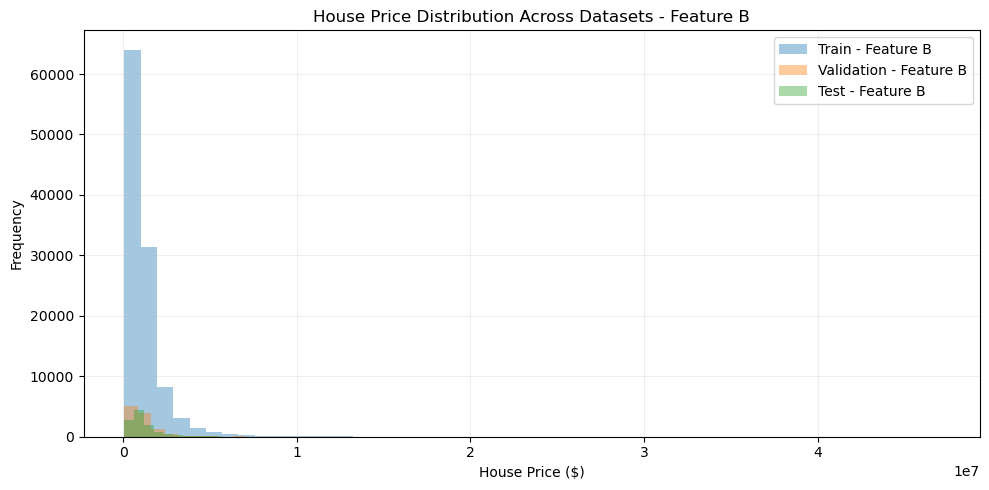

In [74]:
plt.figure(figsize=(10, 5))

plt.hist(y_train, bins=50, alpha=0.4, label="Train - Feature B")
plt.hist(y_val, bins=50, alpha=0.4, label="Validation - Feature B")
plt.hist(y_test_final, bins=50, alpha=0.4, label="Test - Feature B")

plt.xlabel("House Price ($)")
plt.ylabel("Frequency")
plt.title("House Price Distribution Across Datasets - Feature B")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [75]:
test_results_df = pd.DataFrame({
    "Actual_Price": np.asarray(y_test_final).ravel()})

bins = [
    0,
    300000,
    750000,
    2000000,
    5000000,
    10000000,
    np.inf]

labels = [
    "Under $300K",
    "$300K - $750K",
    "$750K - $2M",
    "$2M - $5M",
    "$5M - $10M",
    "Over $10M"]

test_results_df["Price_Band"] = pd.cut(
    test_results_df["Actual_Price"],
    bins=bins,
    labels=labels,
    include_lowest=True)

price_summary = test_results_df.groupby(
    "Price_Band",
    observed=False).agg(
    Number_of_Properties=("Actual_Price", "count"),
    Average_Price=("Actual_Price", "mean"),
    Minimum_Price=("Actual_Price", "min"),
    Maximum_Price=("Actual_Price", "max"))

price_summary = price_summary.round(2)

display(price_summary)


,Number_of_Properties,Average_Price,Minimum_Price,Maximum_Price
Price_Band,,,,
Under $300K,270,234154.36,70000.0,300000.0
$300K - $750K,3841,555890.75,301000.0,750000.0
$750K - $2M,5535,1179711.30,750385.0,2000000.0
$2M - $5M,1268,2921811.25,2000300.0,5000000.0
$5M - $10M,150,6551455.55,5050000.0,10000000.0
Over $10M,48,14862632.29,10200000.0,28066970.0


In [76]:

y_true = np.asarray(y_test_final).ravel()

test_results_df = pd.DataFrame({
    "Actual_Price": y_true})

test_results_df["Price_Band"] = pd.cut(
    test_results_df["Actual_Price"],
    bins=bins,
    labels=labels,
    include_lowest=True)

predictions = {
    "Linear Regression": lr_test_pred_B,
    "Decision Tree": dt_test_pred_B,
    "Random Forest": rf_test_pred_B,
    "XGBoost": xgb_test_pred_B,
    "LightGBM": lgb_test_pred_B}


band_results = []

for model_name, y_pred in predictions.items():
    y_pred = np.asarray(y_pred).ravel()

    assert len(y_pred) == len(y_true), (
        f"{model_name}: prediction length does not match test data.")

    for band in labels:
        mask = (test_results_df["Price_Band"] == band).to_numpy()

        actual = y_true[mask]
        predicted = y_pred[mask]

        if len(actual) == 0:
            continue

        metrics = regression_report(actual, predicted)

        band_results.append({
            "Model": model_name,
            "Price_Band": band,
            "Count": len(actual),
            **metrics})

price_band_comparison = pd.DataFrame(band_results)

display(
    price_band_comparison.style.format({
        "Count": "{:.0f}",
        "R2": "{:.2f}%",
        "MAE": "${:,.2f}",
        "RMSE": "${:,.2f}",
        "MedianAbsoluteError": "${:,.2f}",
        "MDAPE": "{:.2f}%"}))


,Model,Price_Band,Count,R2,MAE,RMSE,MedianAbsoluteError,MDAPE
0,Linear Regression,Under $300K,270,-7999.15%,"$383,535.69","$493,603.76","$329,862.32",138.26%
1,Linear Regression,$300K - $750K,3841,-631.87%,"$252,770.60","$328,055.79","$207,539.18",37.31%
2,Linear Regression,$750K - $2M,5535,-33.30%,"$268,512.88","$386,882.34","$200,695.76",17.94%
3,Linear Regression,$2M - $5M,1268,-52.76%,"$616,893.72","$925,252.08","$396,618.61",14.22%
4,Linear Regression,$5M - $10M,150,-308.39%,"$2,005,737.87","$2,508,610.69","$1,853,404.13",28.46%
5,Linear Regression,Over $10M,48,-298.74%,"$7,539,279.03","$9,128,229.61","$5,851,244.85",50.70%
6,Decision Tree,Under $300K,270,-1291.93%,"$148,535.71","$204,628.81","$108,707.23",43.56%
7,Decision Tree,$300K - $750K,3841,-375.53%,"$104,080.34","$264,435.72","$66,753.73",12.42%
8,Decision Tree,$750K - $2M,5535,8.80%,"$216,068.98","$320,001.75","$151,701.35",13.86%
9,Decision Tree,$2M - $5M,1268,-53.01%,"$630,364.84","$926,009.10","$447,516.41",16.17%


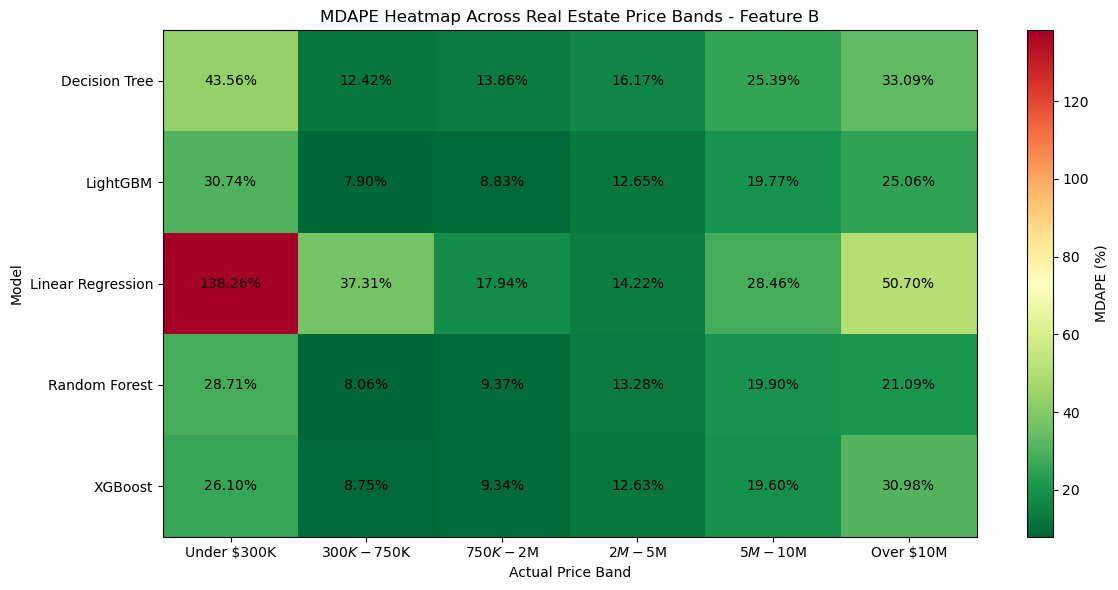

In [77]:
price_order = [
    "Under $300K",
    "$300K - $750K",
    "$750K - $2M",
    "$2M - $5M",
    "$5M - $10M",
    "Over $10M"]

heatmap_data = price_band_comparison.pivot(
    index="Model",
    columns="Price_Band",
    values="MDAPE").reindex(columns=price_order)

plt.figure(figsize=(12, 6))

plt.imshow(
    heatmap_data,
    cmap="RdYlGn_r",
    aspect="auto")

plt.colorbar(label="MDAPE (%)")

for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        value = heatmap_data.iloc[i, j]
        if pd.notna(value):
            plt.text(
                j, i,
                f"{value:.2f}%",
                ha="center",
                va="center",
                color="black")

plt.xticks(np.arange(len(heatmap_data.columns)),
    heatmap_data.columns)

plt.yticks(np.arange(len(heatmap_data.index)),
    heatmap_data.index)

plt.title("MDAPE Heatmap Across Real Estate Price Bands - Feature B")
plt.xlabel("Actual Price Band")
plt.ylabel("Model")

plt.tight_layout()
plt.show()

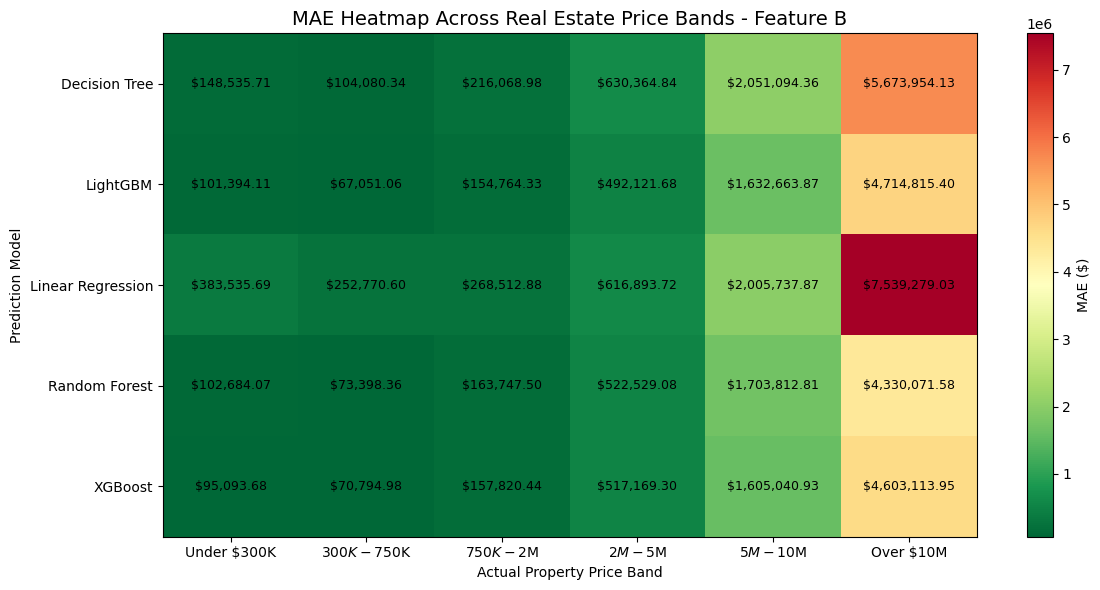

In [85]:
mae_data = price_band_comparison.pivot(
    index="Model",
    columns="Price_Band",
    values="MAE").reindex(columns=price_order)

plt.figure(figsize=(12, 6))

plt.imshow(
    mae_data,
    cmap="RdYlGn_r",
    aspect="auto")

plt.colorbar(label="MAE ($)")

for i in range(len(mae_data.index)):
    for j in range(len(mae_data.columns)):
        value = mae_data.iloc[i, j]
        if pd.notna(value):
            plt.text(
                j, i,
                f"${value:,.2f}",
                ha="center",
                va="center",
                color="black",
                fontsize=9)

plt.xticks(np.arange(len(mae_data.columns)), mae_data.columns)

plt.yticks(np.arange(len(mae_data.index)), mae_data.index)

plt.title("MAE Heatmap Across Real Estate Price Bands - Feature B", fontsize=14)

plt.xlabel("Actual Property Price Band")
plt.ylabel("Prediction Model")

plt.tight_layout()
plt.show()


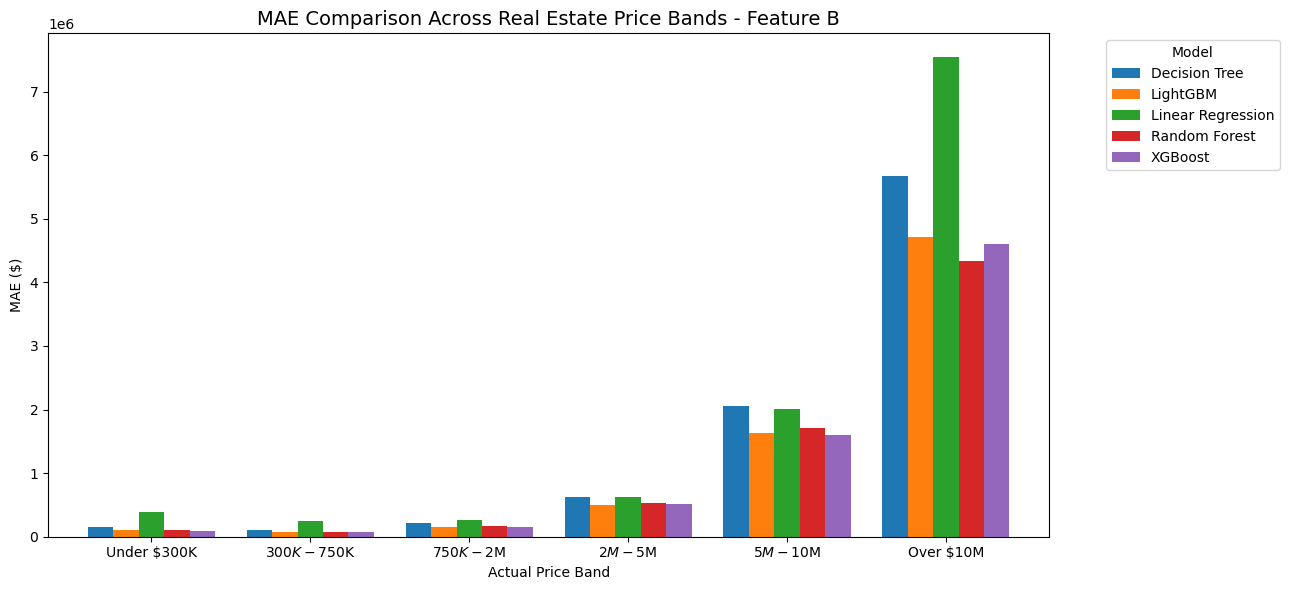

In [86]:
price_order = [
    "Under $300K",
    "$300K - $750K",
    "$750K - $2M",
    "$2M - $5M",
    "$5M - $10M",
    "Over $10M"]

mae_data = price_band_comparison.pivot(
    index="Price_Band",
    columns="Model",
    values="MAE").reindex(price_order)

ax = mae_data.plot(kind="bar", figsize=(13, 6), width=0.8)

plt.title("MAE Comparison Across Real Estate Price Bands - Feature B",
    fontsize=14)

plt.xlabel("Actual Price Band")
plt.ylabel("MAE ($)")

plt.xticks(rotation=0)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.05, 1),
    loc="upper left")

plt.tight_layout()
plt.show()


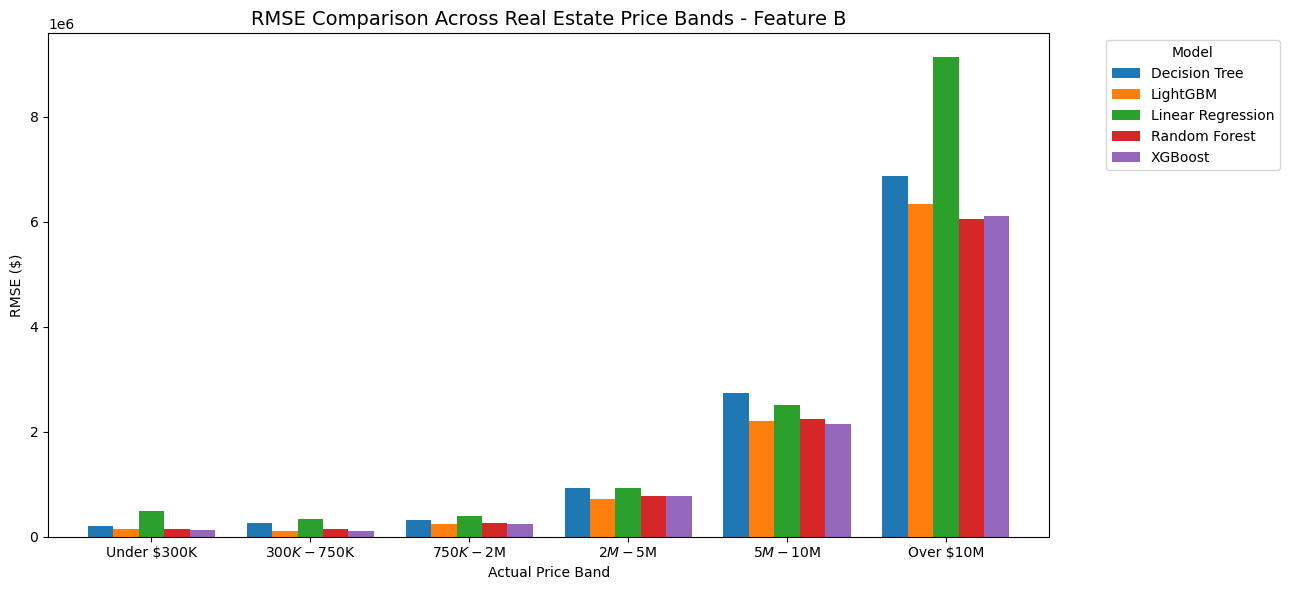

In [87]:
rmse_data = price_band_comparison.pivot(
    index="Price_Band",
    columns="Model",
    values="RMSE").reindex(price_order)

ax = rmse_data.plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8)

plt.title("RMSE Comparison Across Real Estate Price Bands - Feature B", fontsize=14)

plt.xlabel("Actual Price Band")
plt.ylabel("RMSE ($)")

plt.xticks(rotation=0)

plt.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.tight_layout()
plt.show()


In [88]:

best_model_by_band = (
    price_band_comparison
    .dropna(subset=["MDAPE"])
    .sort_values("MDAPE")
    .groupby("Price_Band", observed=False)
    .first()
    .reset_index())

price_order = [
    "Under $300K",
    "$300K - $750K",
    "$750K - $2M",
    "$2M - $5M",
    "$5M - $10M",
    "Over $10M"]

best_model_by_band["Price_Band"] = pd.Categorical(
    best_model_by_band["Price_Band"],
    categories=price_order,
    ordered=True)

best_model_by_band = best_model_by_band.sort_values(
    "Price_Band").reset_index(drop=True)

display(
    best_model_by_band[[
        "Price_Band",
        "Model",
        "Count",
        "MDAPE",
        "MAE",
        "RMSE"
    ]].style.format({
        "Count": "{:.0f}",
        "MDAPE": "{:.2f}%",
        "MAE": "${:,.2f}",
        "RMSE": "${:,.2f}"}))


,Price_Band,Model,Count,MDAPE,MAE,RMSE
0,Under $300K,XGBoost,270,26.10%,"$95,093.68","$136,525.48"
1,$300K - $750K,LightGBM,3841,7.90%,"$67,051.06","$108,963.91"
2,$750K - $2M,LightGBM,5535,8.83%,"$154,764.33","$236,213.02"
3,$2M - $5M,XGBoost,1268,12.63%,"$517,169.30","$769,871.48"
4,$5M - $10M,XGBoost,150,19.60%,"$1,605,040.93","$2,151,783.06"
5,Over $10M,Random Forest,48,21.09%,"$4,330,071.58","$6,055,559.34"


In [89]:
print("=" * 60)
print("MODEL EVALUATION INSIGHTS - FEATURE B")
print("=" * 60)

best_overall = (
    test_results_B_df
    .sort_values("MDAPE", ascending=True)
    .iloc[0])

print("\n1. BEST OVERALL MODEL")
print(f"Model: {best_overall['Model']}")
print(f"R2: {best_overall['R2']:.2f}%")
print(f"MAE: ${best_overall['MAE']:,.2f}")
print(f"RMSE: ${best_overall['RMSE']:,.2f}")
print(f"MDAPE: {best_overall['MDAPE']:.2f}%")

print("\n2. BEST MODEL BY PRICE BAND")

for _, row in best_model_by_band.iterrows():
    print(
        f"{row['Price_Band']}: "
        f"{row['Model']} "
        f"(MDAPE: {row['MDAPE']:.2f}%)")

average_band_error = (
    price_band_comparison
    .groupby("Price_Band", observed=False)["MDAPE"].mean().dropna())

if not average_band_error.empty:
    worst_band = average_band_error.idxmax()
    best_band = average_band_error.idxmin()

    print("\n3. PRICE BAND PERFORMANCE")
    print(f"Best-performing price band: {best_band} "
        f"(Average MDAPE: {average_band_error[best_band]:.2f}%)")

    print(f"Most challenging price band: {worst_band} "
        f"(Average MDAPE: {average_band_error[worst_band]:.2f}%)")

print("\n" + "=" * 60)


MODEL EVALUATION INSIGHTS - FEATURE B

1. BEST OVERALL MODEL
Model: LightGBM - Feature B
R2: 82.90%
MAE: $201,292.40
RMSE: $574,334.37
MDAPE: 9.10%

2. BEST MODEL BY PRICE BAND
Under $300K: XGBoost (MDAPE: 26.10%)
$300K - $750K: LightGBM (MDAPE: 7.90%)
$750K - $2M: LightGBM (MDAPE: 8.83%)
$2M - $5M: XGBoost (MDAPE: 12.63%)
$5M - $10M: XGBoost (MDAPE: 19.60%)
Over $10M: Random Forest (MDAPE: 21.09%)

3. PRICE BAND PERFORMANCE
Best-performing price band: $750K - $2M (Average MDAPE: 11.87%)
Most challenging price band: Under $300K (Average MDAPE: 53.47%)

